In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
import scanpy as sc
import anndata
import pandas as pd
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import ndtest
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import DistanceMetric
import numpy as np
import os
from matplotlib import font_manager
import matplotlib.patches as mpatches
from scipy.ndimage import gaussian_filter
from matplotlib.legend_handler import HandlerTuple
font_manager.fontManager.addfont("../../../.././arial.ttf")
import numpy as np
import matplotlib.pyplot as plt
from brokenaxes import brokenaxes

plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 17,
    "pdf.fonttype": 42,
})
plt.rcParams["hatch.linewidth"] = 1
# legend_fig = plt.figure(figsize=(3, 1.5))

# legend = legend_fig.legend(
#     handles,
#     labels,
#     loc="center",
#     markerscale=6,
#     scatterpoints=1,
#     prop={"size": 8, "weight": "bold"},
#     frameon=True,
#     facecolor="white",
#     edgecolor="lightgray",
#     framealpha=0.1
# )

# # Crop the PDF to the legend
# legend_fig.canvas.draw()
# bbox = legend.get_window_extent().transformed(
#     legend_fig.dpi_scale_trans.inverted()
# )

# legend_fig.savefig(
#     "umap_legend.pdf",
#     bbox_inches=bbox,
#     pad_inches=0.05
# )

# plt.show()


/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


real_data: View of AnnData object with n_obs × n_vars = 600 × 100
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 100
cellDiffGen gene num, r2,pearsonr 100 0.9437362918138424 0.9885999043341304
squidiff_data: AnnData object with n_obs × n_vars = 600 × 100
yes
Squidiff gene num, r2,pearsonr 100 0.9615298627486295 0.9820888129640813
5.3391128 5.638178296951909
real_data: View of AnnData object with n_obs × n_vars = 600 × 200
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 200
cellDiffGen gene num, r2,pearsonr 200 0.9588250051826664 0.9815677019952453
squidiff_data: AnnData object with n_obs × n_vars = 600 × 200
yes
Squidiff gene num, r2,pearsonr 200 0.7999679698696455 0.98535002327744
9.985522 9.124525687465336
real_data: View of AnnData object with n_obs × n_vars = 600 × 203
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 203
cellDiffGen gene num, r2,pearsonr 203 0.9838500834521899 0.9946954952761008
squidiff_

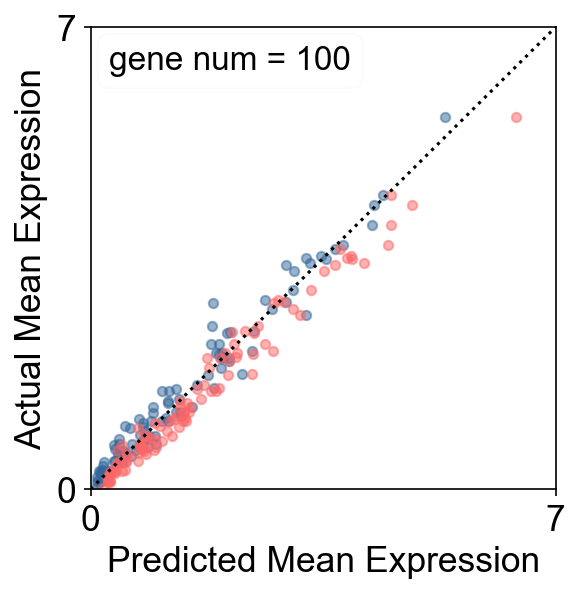

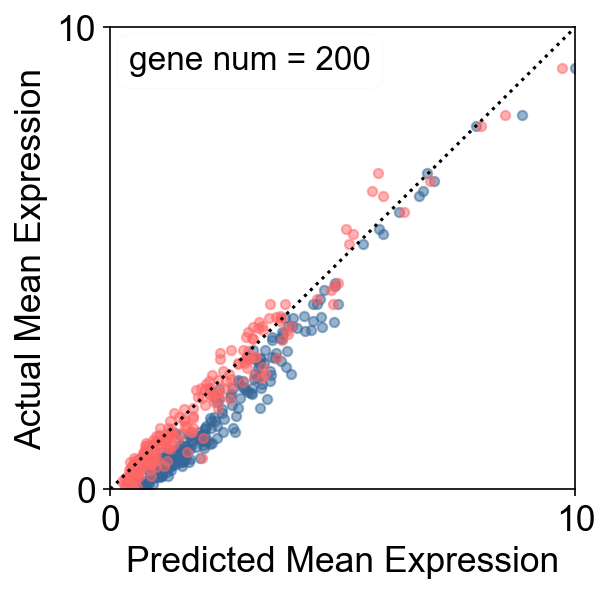

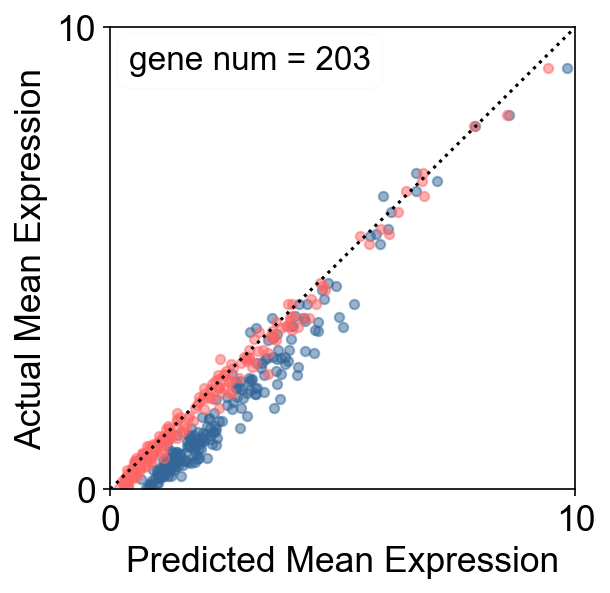

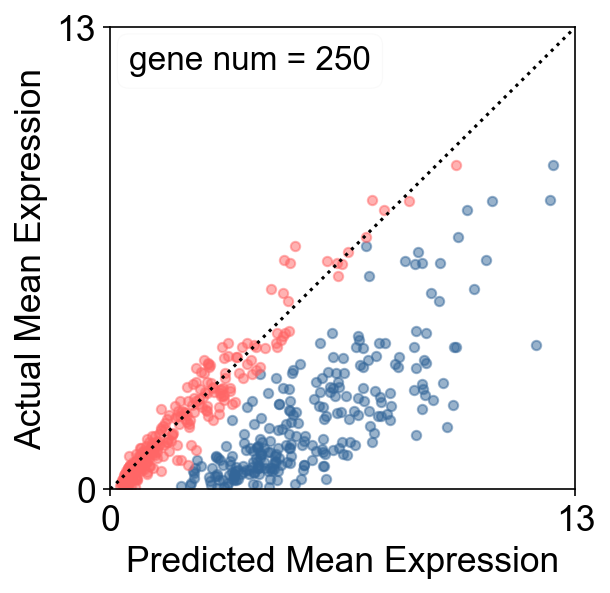

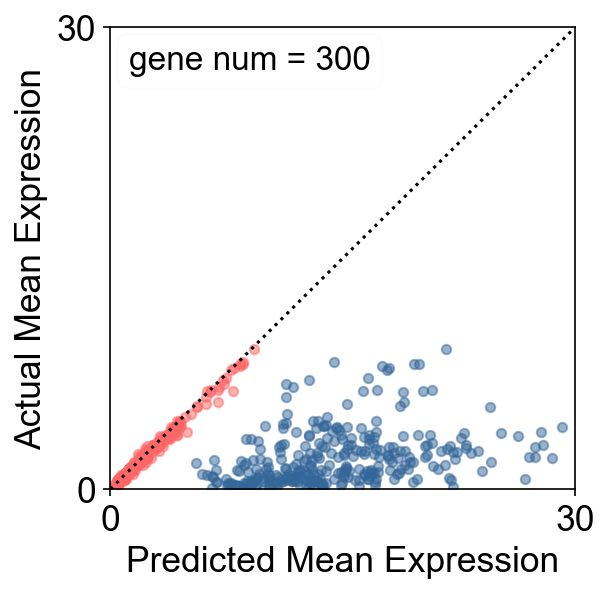

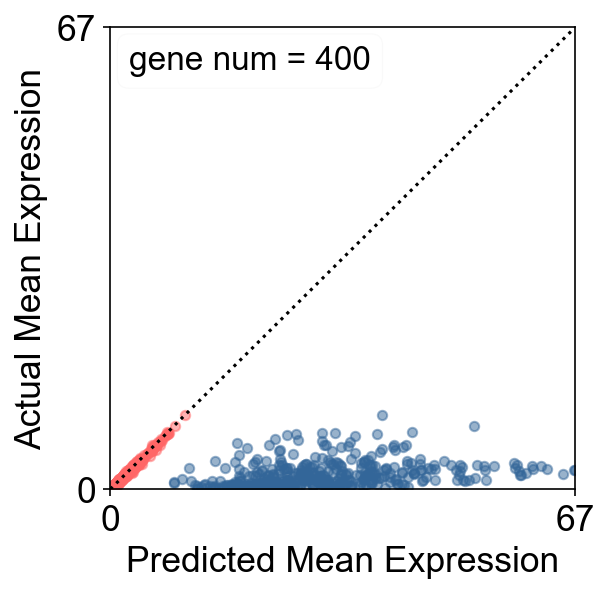

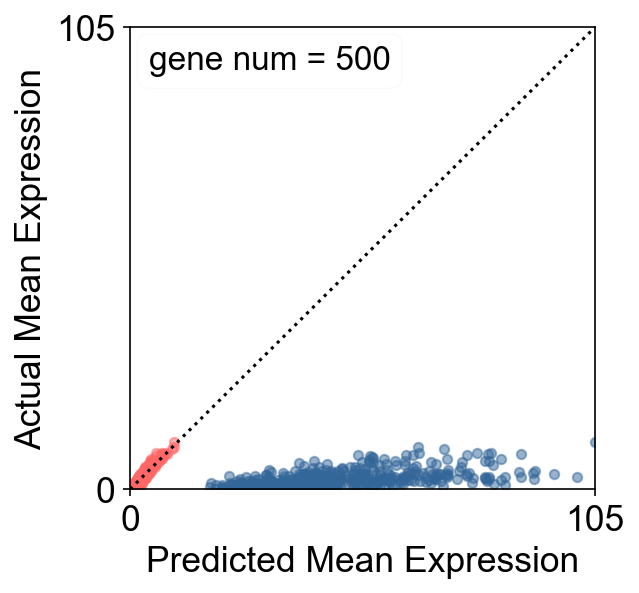

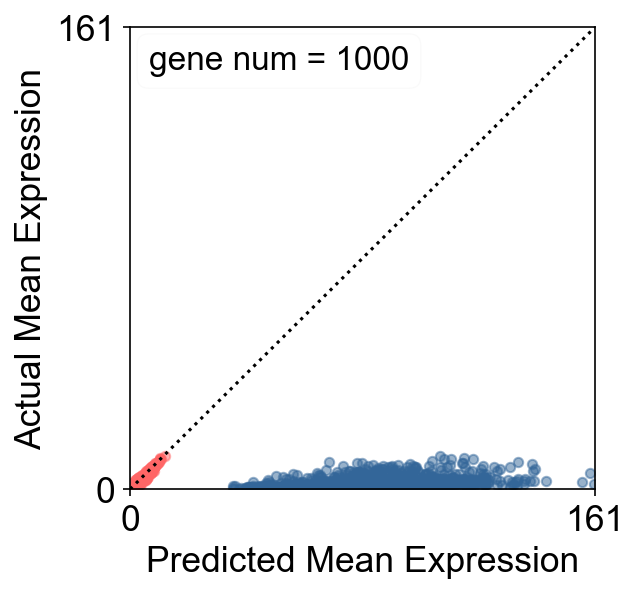

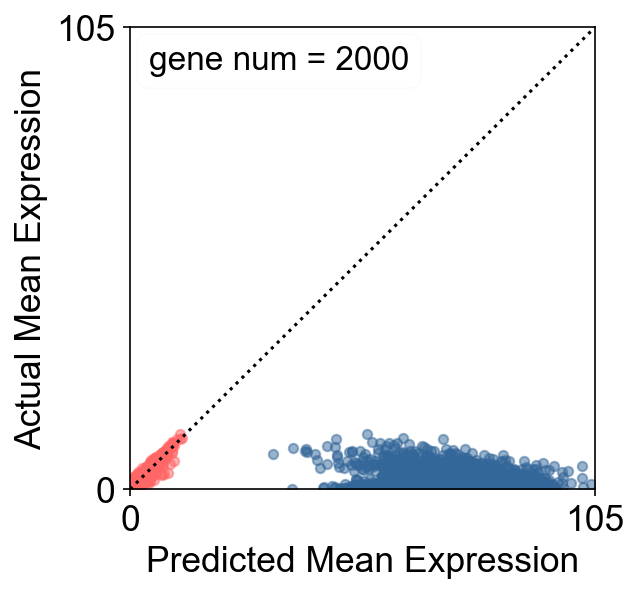

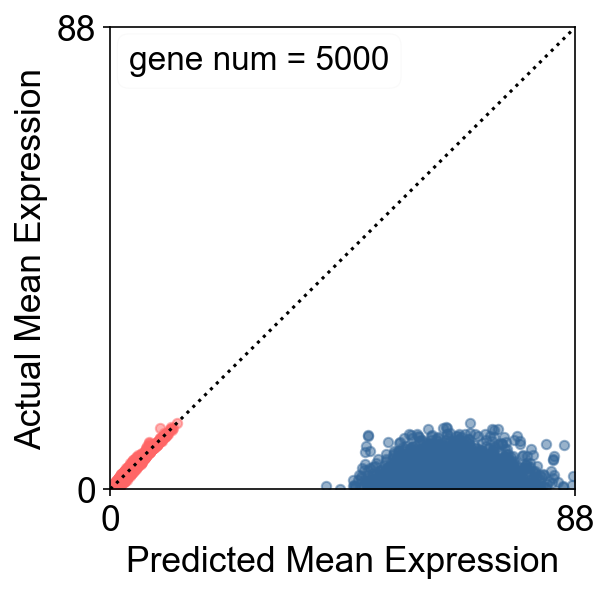

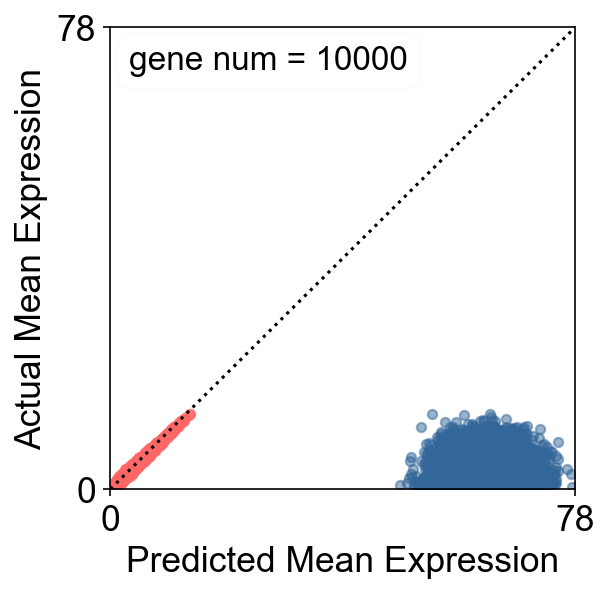

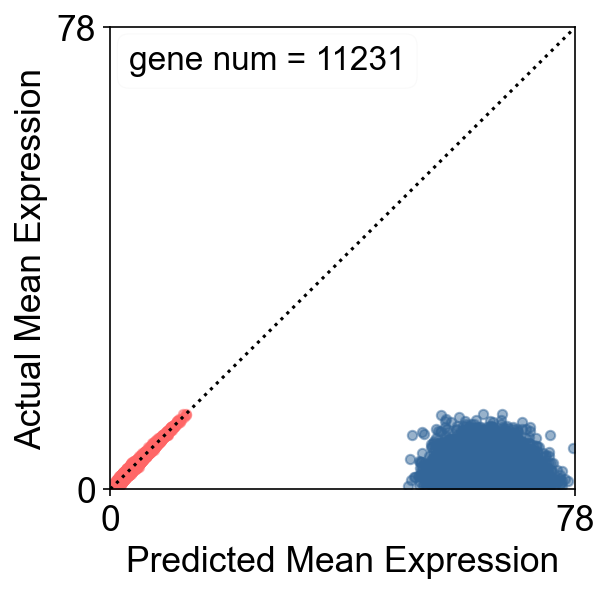

In [2]:
with open("results.txt", "w") as f:
    for i in [100,200,203,250,300,400,500,1000,2000,5000,10000,11231]:
        real_data_origin = sc.read_h5ad(f"../../input/diff_test_gene_num_{i}.h5ad")
        real_data = real_data_origin[real_data_origin.obs['Group']==3]
        # real_data = sc.read_h5ad("../../input/test_day0_data.h5ad")
        print("real_data:",real_data)

        predict_data = sc.read_h5ad(f"../experiments/exp5_day0_predict_day3_gene_num_{i}/interception_predict_to_day_3.h5ad")
        print("predict_data:",predict_data)
        #   check_nan(predict_data, "predict_data")
        #   check_nan(real_data, "real_data")
        r2, pearsonr,real_mean_1,new_mean = calc_r2_pearson(real_data,predict_data)
        print("cellDiffGen gene num, r2,pearsonr",i, r2, pearsonr)
        print(
            f"cellDiffGen gene num, r2,pearsonr: {i}, {r2:.3f}, {pearsonr:.3f}",
            file=f
        )
        squidiff_data = sc.read_h5ad(f"../../squidiff/experiments/squidiff_exp5_extend_day0_predict_day3_gene_num_{i}.h5ad")
        print("squidiff_data:",squidiff_data)
        r2, pearsonr,real_mean_2,squidiff_mean = calc_r2_pearson(real_data,squidiff_data)
        if np.array_equal(real_mean_1, real_mean_2):
            print("yes")
        else:
            print("no")
        print("Squidiff gene num, r2,pearsonr",i, r2, pearsonr)
        print(
            f"Squidiff gene num, r2,pearsonr: {i}, {r2:.3f}, {pearsonr:.3f}",
            file=f
        )
        # squidiff_mean = predict_sample_dict["squidiff_day0to3_5"].detach().cpu().numpy().mean(axis=0)

        fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=150)

        plt.scatter(
            squidiff_mean,
            real_mean_1,
            s=20,
            c='#336699',
            # label='day0to3_squidiff',
            alpha=0.5
        )

        plt.scatter(
            new_mean,
            real_mean_2,
            s=20,
            c='#FF6666',
            # label='day0to3_new_method',
            alpha=0.5
        )
        limit = np.ceil(max(max(np.max(squidiff_mean),np.max(new_mean)), np.max(real_mean_2)))
        print(np.max(squidiff_mean),np.max(real_mean_2))
        plt.plot([0, limit], [0, limit], color="black", linestyle=":")
        plt.xlim([0, limit])
        plt.ylim([0, limit])
        if limit <= 8:
            ticks = np.arange(0, limit + 1, 10)
        else:    
            ticks = np.arange(0, limit + 1, 200)
            
        ticks = np.append(ticks, limit)
        ticks = np.unique(ticks)
        plt.xticks(ticks)
        plt.yticks(ticks)
        # print("max",max(np.max(predict), np.max(real)))
        plt.xlabel(f"Predicted Mean Expression")
        plt.ylabel(f"Actual Mean Expression")
        # plt.legend(loc='upper right',bbox_to_anchor=(0.5, -0.25))
        # plt.show()
        ax.text(0.04, 0.96, f"gene num = {i:.0f}",
        transform=ax.transAxes, va="top", ha="left", fontsize=16, linespacing=1.4,
        bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.1))
        fig.savefig(os.path.join(f"day0_predict_day3_compare_gene_num_{i}.pdf"), bbox_inches="tight")

## per gene (compare method)

In [3]:
from scipy.stats import ks_2samp
import numpy as np
from statannotations.Annotator import Annotator
from matplotlib.patches import Patch

def ks_per_gene(x1, x2):
    # x1: torch tensor (cells × genes)
    # x2: AnnData

    # x1_np = x1.detach().cpu().numpy()
    x1_np = x1.X if isinstance(x1.X, np.ndarray) else x1.X.toarray()
    x2_np = x2.X if isinstance(x2.X, np.ndarray) else x2.X.toarray()

    ks_stats = []
    p_values = []
    # print("len",len(range(x1_np.shape[1])))
    for g in range(x1_np.shape[1]):  # loop over genes
        stat, p = ks_2samp(x1_np[:, g], x2_np[:, g])
        ks_stats.append(stat)
        p_values.append(p)

    return np.array(ks_stats), np.array(p_values)

real_data: View of AnnData object with n_obs × n_vars = 600 × 100
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 100
squidiff_data: AnnData object with n_obs × n_vars = 600 × 100
200


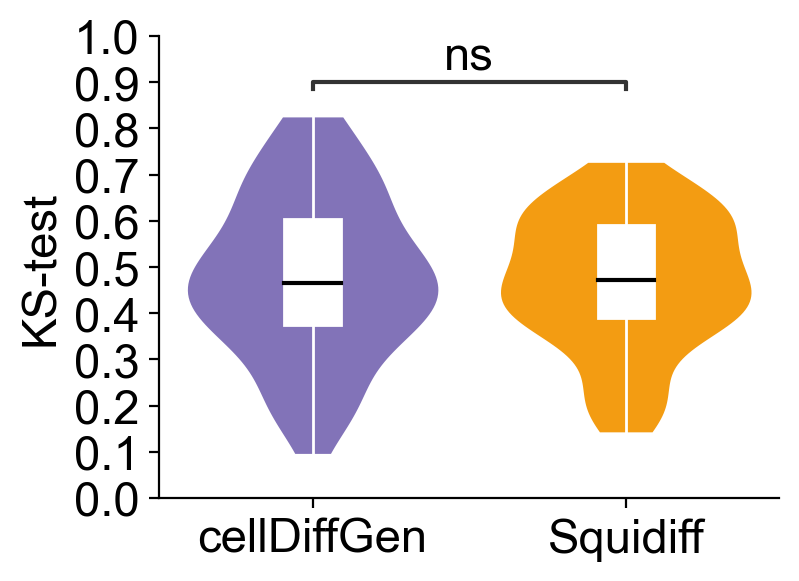

real_data: View of AnnData object with n_obs × n_vars = 600 × 200
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 200
squidiff_data: AnnData object with n_obs × n_vars = 600 × 200
400


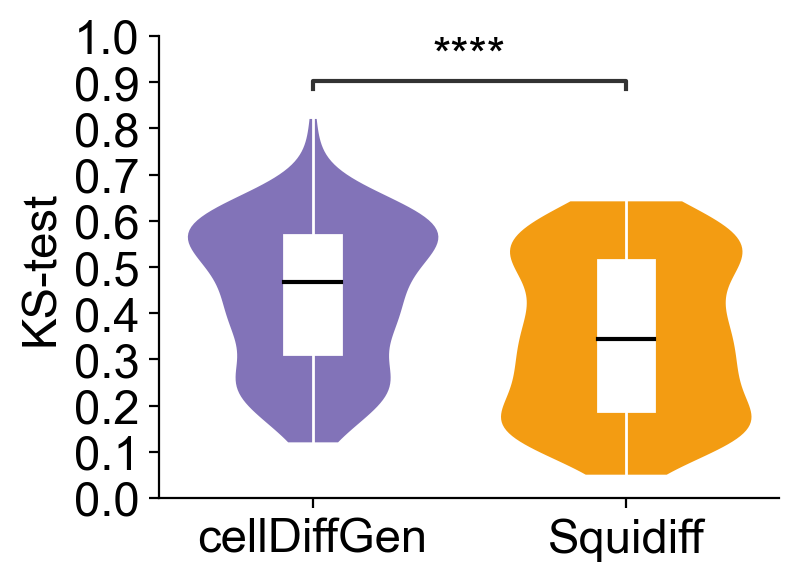

real_data: View of AnnData object with n_obs × n_vars = 600 × 203
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 203
squidiff_data: AnnData object with n_obs × n_vars = 600 × 203
406


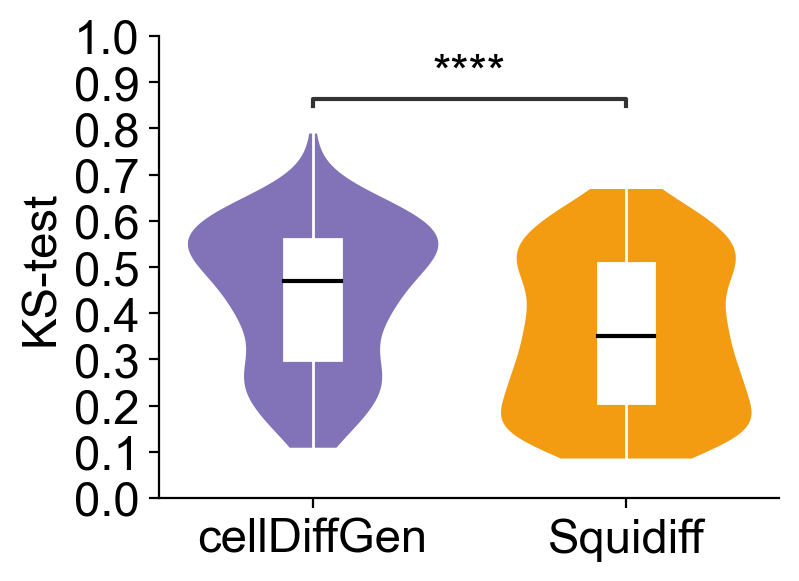

real_data: View of AnnData object with n_obs × n_vars = 600 × 250
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 250
squidiff_data: AnnData object with n_obs × n_vars = 600 × 250
500


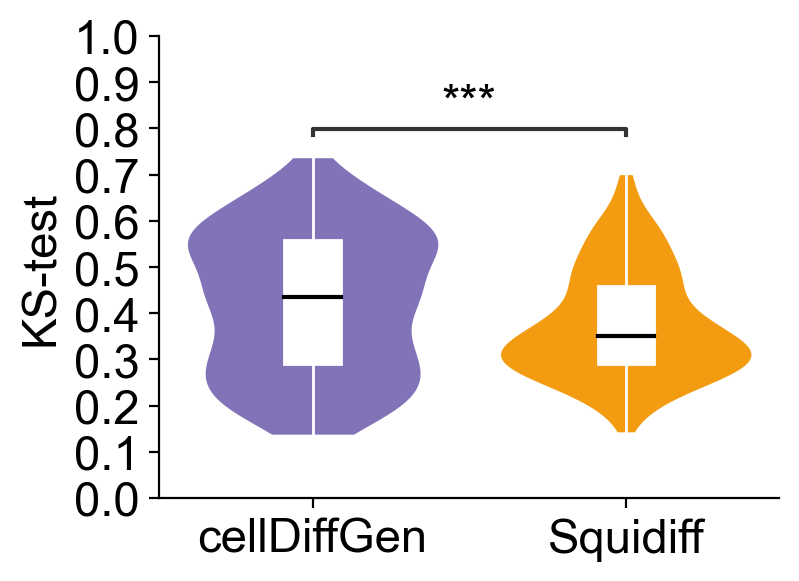

real_data: View of AnnData object with n_obs × n_vars = 600 × 300
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 300
squidiff_data: AnnData object with n_obs × n_vars = 600 × 300
600


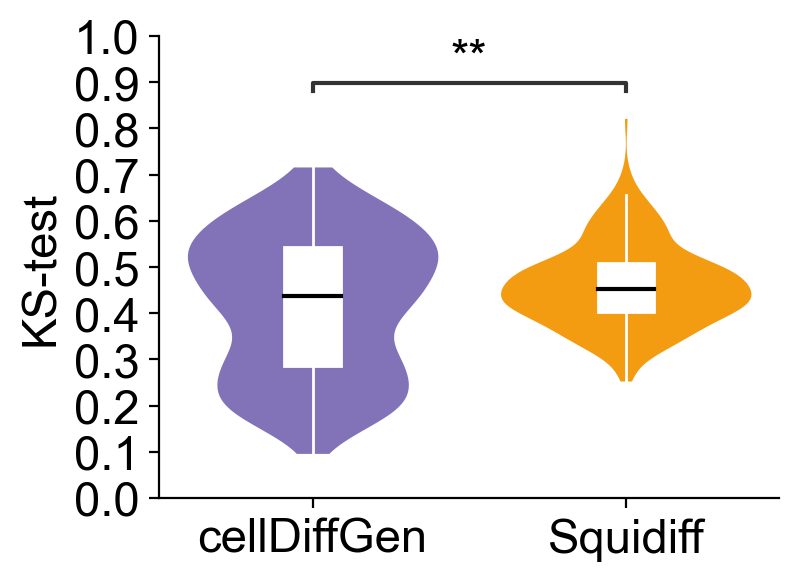

real_data: View of AnnData object with n_obs × n_vars = 600 × 400
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 400
squidiff_data: AnnData object with n_obs × n_vars = 600 × 400
800


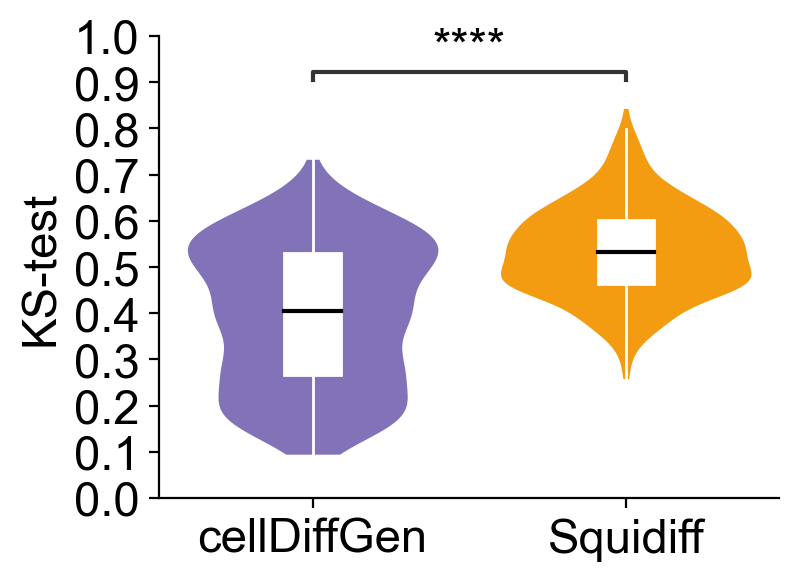

real_data: View of AnnData object with n_obs × n_vars = 600 × 500
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 500
squidiff_data: AnnData object with n_obs × n_vars = 600 × 500
1000


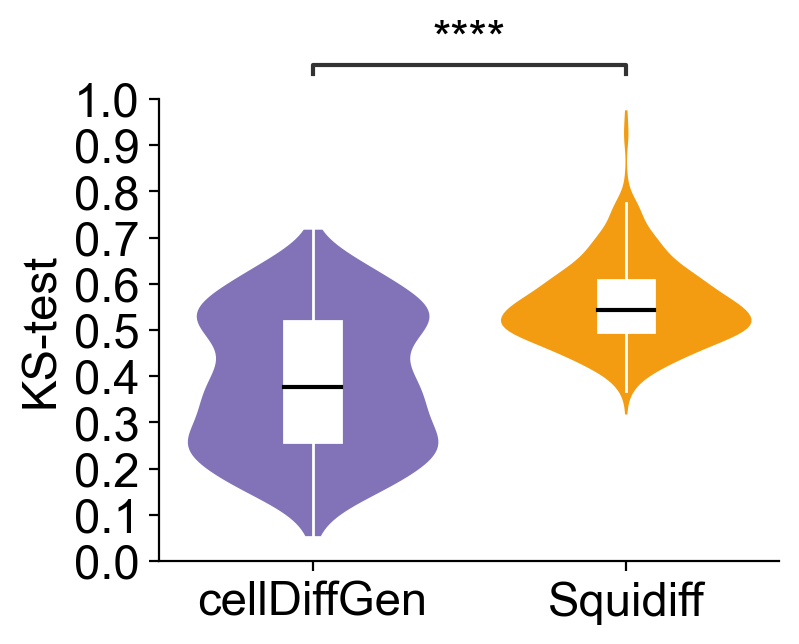

real_data: View of AnnData object with n_obs × n_vars = 600 × 1000
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 1000
squidiff_data: AnnData object with n_obs × n_vars = 600 × 1000
2000


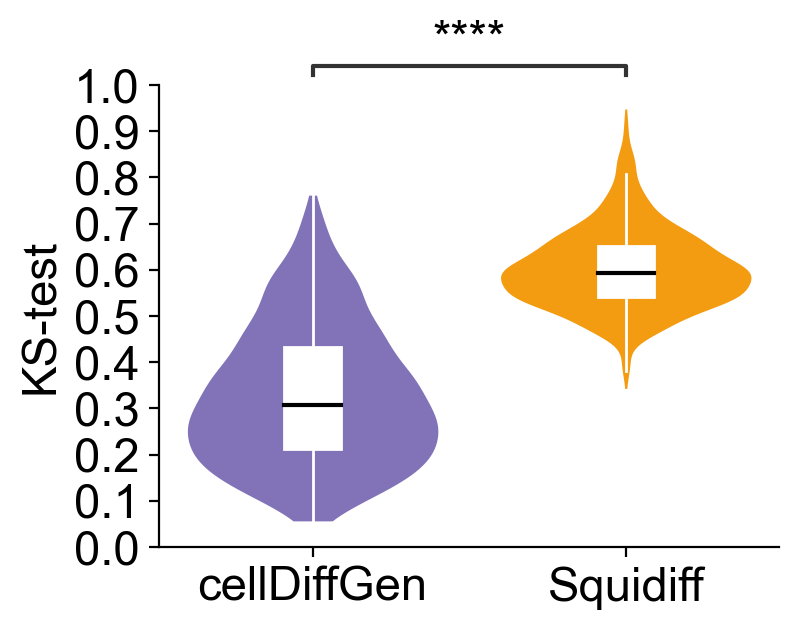

real_data: View of AnnData object with n_obs × n_vars = 600 × 2000
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 2000
squidiff_data: AnnData object with n_obs × n_vars = 600 × 2000
4000


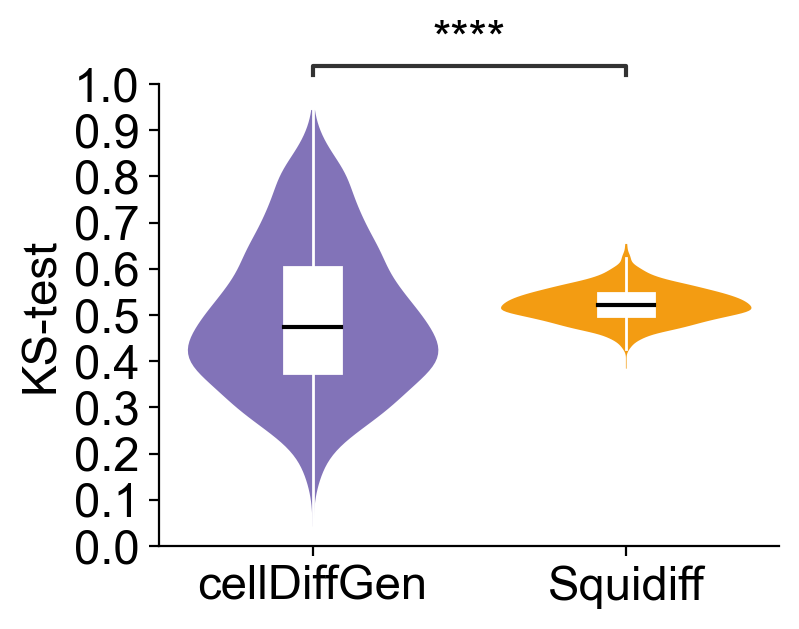

real_data: View of AnnData object with n_obs × n_vars = 600 × 5000
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 5000
squidiff_data: AnnData object with n_obs × n_vars = 600 × 5000
10000


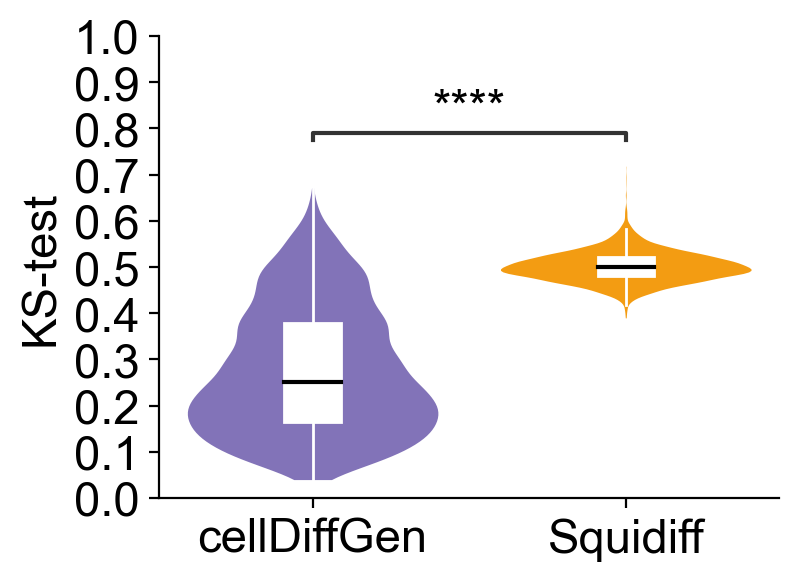

real_data: View of AnnData object with n_obs × n_vars = 600 × 10000
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 10000
squidiff_data: AnnData object with n_obs × n_vars = 600 × 10000
20000


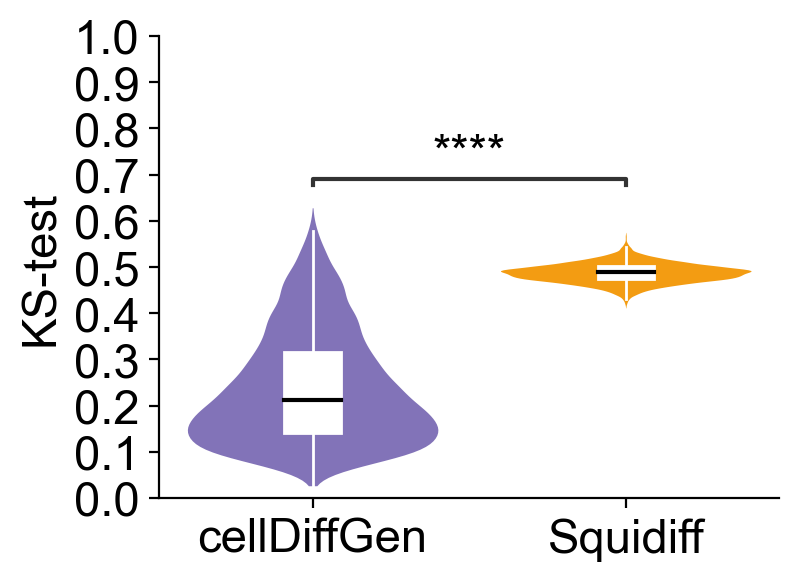

real_data: View of AnnData object with n_obs × n_vars = 600 × 11231
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 11231
squidiff_data: AnnData object with n_obs × n_vars = 600 × 11231
22462


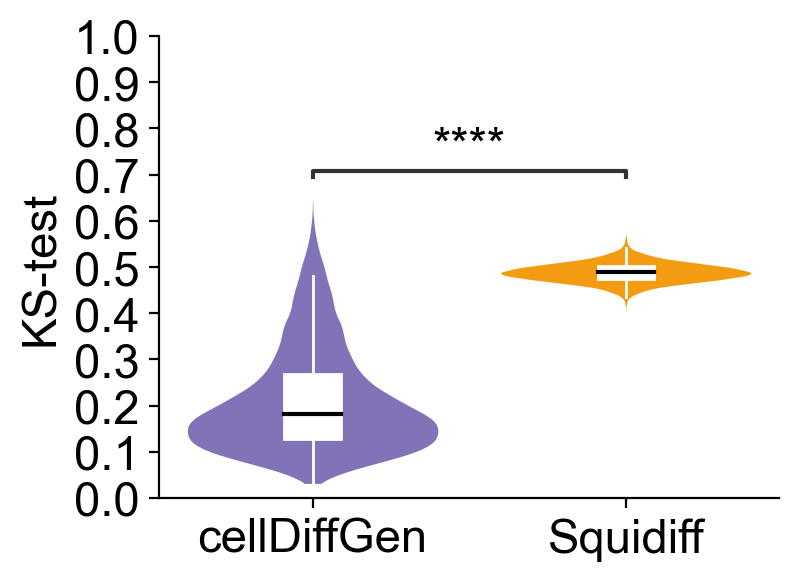

In [4]:
for i in [100,200,203,250,300,400,500,1000,2000,5000,10000,11231]:
    real_data_origin = sc.read_h5ad(f"../../input/diff_test_gene_num_{i}.h5ad")
    real_adata = real_data_origin[real_data_origin.obs['Group'] == 3]
    print("real_data:", real_adata)

    predict_data = sc.read_h5ad(
        f"../experiments/exp5_day0_predict_day3_gene_num_{i}/interception_predict_to_day_3.h5ad"
    )
    print("predict_data:", predict_data)

    squidiff_data = sc.read_h5ad(
        f"../../squidiff/experiments/squidiff_exp5_extend_day0_predict_day3_gene_num_{i}.h5ad"
    )
    print("squidiff_data:", squidiff_data)
    
    ks_stats_1, p_values_1 = ks_per_gene(predict_data, real_adata)

    df_ks_1 = pd.DataFrame({
        'Sample': ['cellDiffGen'] * len(ks_stats_1),
        'KS_stat': ks_stats_1,
        # 'neglog10_p_value': -np.log10(np.maximum(p_values_1, 1e-300))
    })

    ks_stats_2, p_values_2 = ks_per_gene(squidiff_data, real_adata)

    df_ks_2 = pd.DataFrame({
        'Sample': ['Squidiff'] * len(ks_stats_2),
        'KS_stat': ks_stats_2,
        # 'neglog10_p_value': -np.log10(np.maximum(p_values_2, 1e-300))
    })

    # combine
    df_ks_all = pd.concat([df_ks_1, df_ks_2], ignore_index=True)
    print(len(df_ks_all))


    # Violin plot for KS statistics
    order = ["cellDiffGen", "Squidiff"]
    colors = ["#8273B8", "#F39C12"]

    fig, ax = plt.subplots(figsize=(4, 3), dpi=200)

    sns.violinplot(
        data=df_ks_all,
        x="Sample", y="KS_stat",
        order=order,
        hue="Sample", hue_order=order,
        palette=colors,
        legend=False,
        cut=0,
        linewidth=0,
        saturation=1,
        alpha=1,
        ax=ax,
        inner='box'
    )

    # White box plots inside the violins
    values = [
        df_ks_all.loc[df_ks_all["Sample"] == name, "KS_stat"]
        for name in order
    ]

    ax.boxplot(
        values,
        positions=[0, 1],
        widths=0.18,
        patch_artist=True,
        showfliers=False,
        showcaps=False,
        manage_ticks=False,
        boxprops=dict(facecolor="white", edgecolor="white", zorder=3),
        medianprops=dict(color="black", linewidth=1.5, zorder=4),
        whiskerprops=dict(color="white", linewidth=1, zorder=4)
    )

    # Compare the two groups of KS statistics
    annotator = Annotator(
        ax, [("cellDiffGen", "Squidiff")],
        data=df_ks_all,
        x="Sample", y="KS_stat",
        order=order
    )
    annotator.configure(
        test="Mann-Whitney",
        # text_format="simple",
        show_test_name=True,
        # test_short_name="Mann–Whitney",
        loc="outside",
        verbose=0
    )
    annotator.apply_and_annotate()

    # Legend above the bracket
    handles = [
        Patch(facecolor=color, edgecolor="#555555", label=name)
        for name, color in zip(order, colors)
    ]
    # ax.legend(
    #     handles=handles,
    #     loc="lower center",
    #     bbox_to_anchor=(0.5, 1.20),
    #     ncol=2,
    #     frameon=False,
    #     fontsize=9
    # )

    ax.set_xlabel("")
    ax.set_ylabel("KS-test")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9, 1])
    ax.tick_params(direction="out")
    ax.grid(False)

    fig.savefig(f"ks_ks_stats_compare_gene_num_{i}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [5]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import seaborn as sns
from sklearn.metrics import pairwise_distances
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())




/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [6]:


def get_pairwise_new(x1, x2, x3, num):
    """
    x1: Squidiff AnnData
    x2: cellDiffGen AnnData
    x3: Real AnnData
    num: Gene number used in the output filename

    All datasets must have the same genes in the same order
    and use the same expression normalization.
    """

    # Check gene names and order
    # if not (
    #     x1.var_names.equals(x3.var_names)
    #     and x2.var_names.equals(x3.var_names)
    # ):
    #     raise ValueError(
    #         "All datasets must have the same genes in the same order."
    #     )

    # print(
    #     "Squidiff, cellDiffGen, real cell numbers:",
    #     x1.n_obs, x2.n_obs, x3.n_obs
    # )
    # print("Number of genes:", x3.var_names, x2.var_names)

    # Directly use original expression matrices.
    # pairwise_distances supports both dense and sparse matrices.
    D_s = pairwise_distances(x1.X, x3.X, metric="euclidean")
    D_n = pairwise_distances(x2.X, x3.X, metric="euclidean")
    print(x1.shape[1],x2.shape[1],x3.shape[1])
    all_distances_s = D_s.min(axis=1) / np.sqrt(x1.shape[1])
    all_distances_n = D_n.min(axis=1) / np.sqrt(x2.shape[1])
    # all_distances_s = D_s.ravel()
    # all_distances_n = D_n.ravel()

    df = pd.DataFrame({
        "Sample": (
            ["cellDiffGen"] * len(all_distances_n)
            + ["Squidiff"] * len(all_distances_s)
        ),
        "distance": np.concatenate([
            all_distances_n,
            all_distances_s
        ])
    })

    order = ["cellDiffGen", "Squidiff"]
    colors = ["#8273B8", "#4AC1B0"]

    fig, ax = plt.subplots(figsize=(4, 4), dpi=200)

    sns.violinplot(
        data=df,
        x="Sample",
        y="distance",
        order=order,
        hue="Sample",
        hue_order=order,
        palette=colors,
        legend=False,
        cut=0,
        linewidth=0,
        saturation=1,
        inner=None,
        ax=ax
    )

    # White box plots inside the violins
    values = [
        df.loc[df["Sample"] == name, "distance"].to_numpy()
        for name in order
    ]

    ax.boxplot(
        values,
        positions=[0, 1],
        widths=0.18,
        patch_artist=True,
        showfliers=False,
        showcaps=False,
        manage_ticks=False,
        boxprops=dict(
            facecolor="white",
            edgecolor="white",
            zorder=3
        ),
        medianprops=dict(
            color="black",
            linewidth=1.5,
            zorder=4
        ),
        whiskerprops=dict(
            color="white",
            linewidth=1,
            zorder=4
        )
    )

    print(df.groupby("Sample")["distance"].agg(["mean", "median", "max"]))

    ax.set_xticks([0, 1])
    ax.set_xticklabels(order)
    ax.set_xlabel("")
    ax.set_ylabel("Nearest cell RMSE")
    ax.set_ylim(bottom=0)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="y", labelsize=15)
    ax.tick_params(direction="out")
    ax.grid(False)

    fig.tight_layout()
    fig.savefig(
        f"nearest_cell_RMSE_original_space_compare_gene_num_{num}_violin.pdf",
        bbox_inches="tight"
    )
    plt.show()

    return df

real_data: View of AnnData object with n_obs × n_vars = 600 × 100
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 100
squidiff_data: AnnData object with n_obs × n_vars = 600 × 100
100 100 100
                 mean    median       max
Sample                                   
Squidiff     1.634152  1.632507  2.035721
cellDiffGen  1.741391  1.742519  2.083553


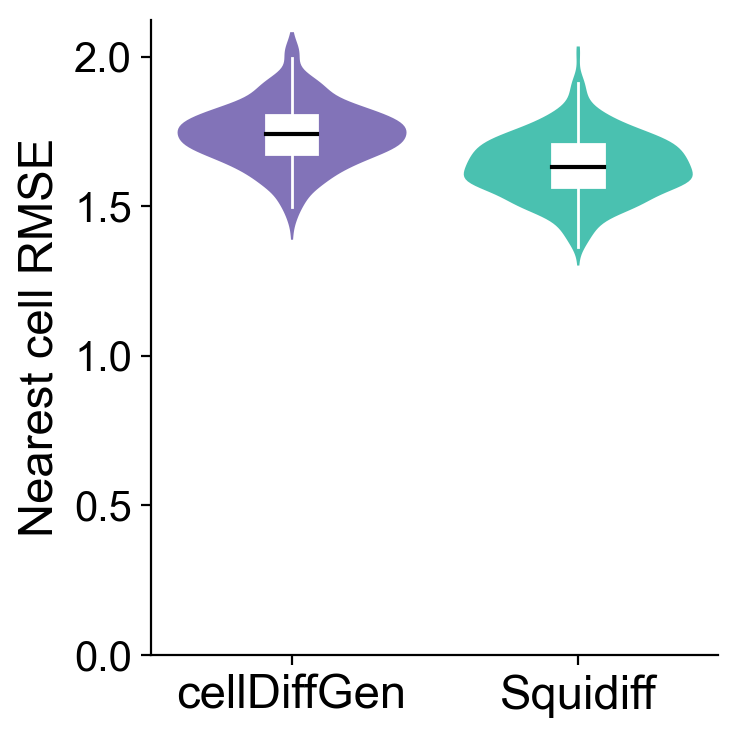

real_data: View of AnnData object with n_obs × n_vars = 600 × 200
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 200
squidiff_data: AnnData object with n_obs × n_vars = 600 × 200
200 200 200
                 mean    median        max
Sample                                    
Squidiff     2.740787  2.479665  13.474337
cellDiffGen  1.742348  1.743001   1.939718


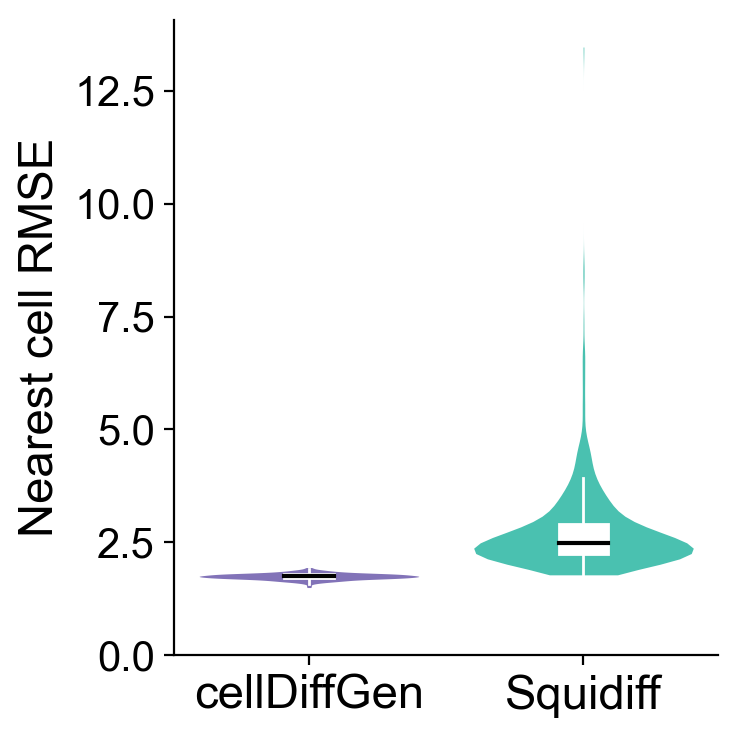

real_data: View of AnnData object with n_obs × n_vars = 600 × 203
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 203
squidiff_data: AnnData object with n_obs × n_vars = 600 × 203
203 203 203
                 mean    median       max
Sample                                   
Squidiff     2.829371  2.600792  9.532333
cellDiffGen  1.727494  1.731999  1.913304


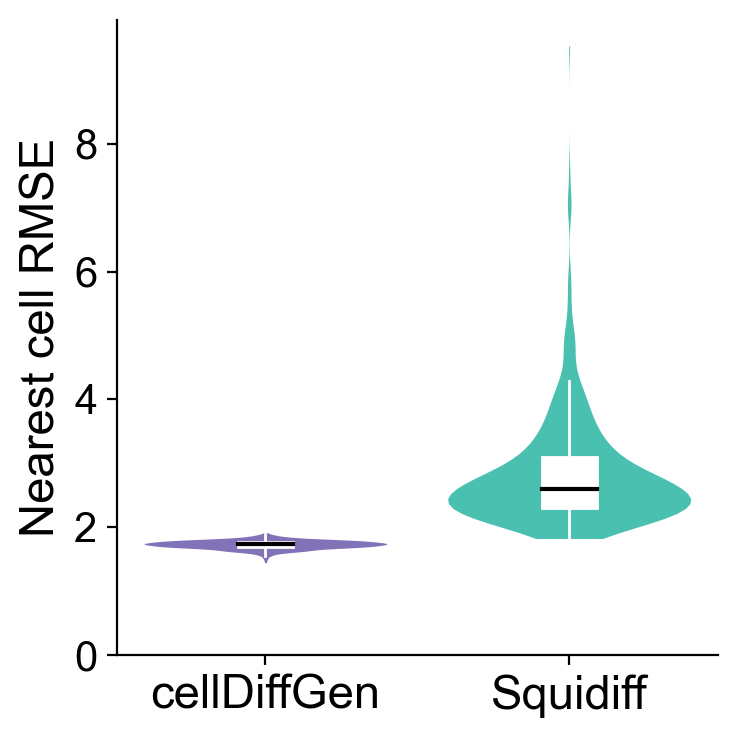

real_data: View of AnnData object with n_obs × n_vars = 600 × 250
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 250
squidiff_data: AnnData object with n_obs × n_vars = 600 × 250
250 250 250
                 mean    median        max
Sample                                    
Squidiff     7.794520  6.212792  43.717076
cellDiffGen  1.727837  1.732737   1.926509


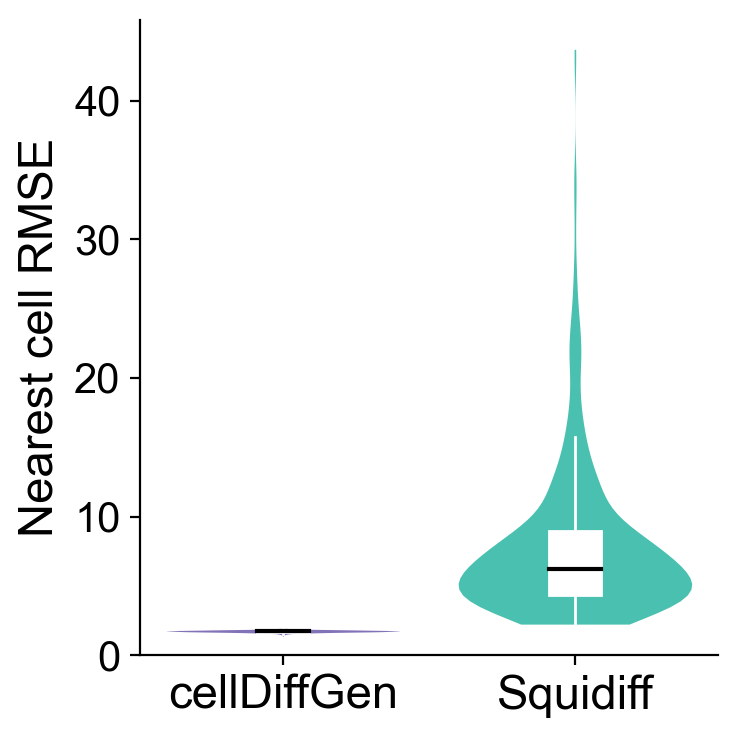

real_data: View of AnnData object with n_obs × n_vars = 600 × 300
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 300
squidiff_data: AnnData object with n_obs × n_vars = 600 × 300
300 300 300
                  mean     median        max
Sample                                      
Squidiff     23.830796  20.415034  91.774569
cellDiffGen   1.708633   1.714352   1.947581


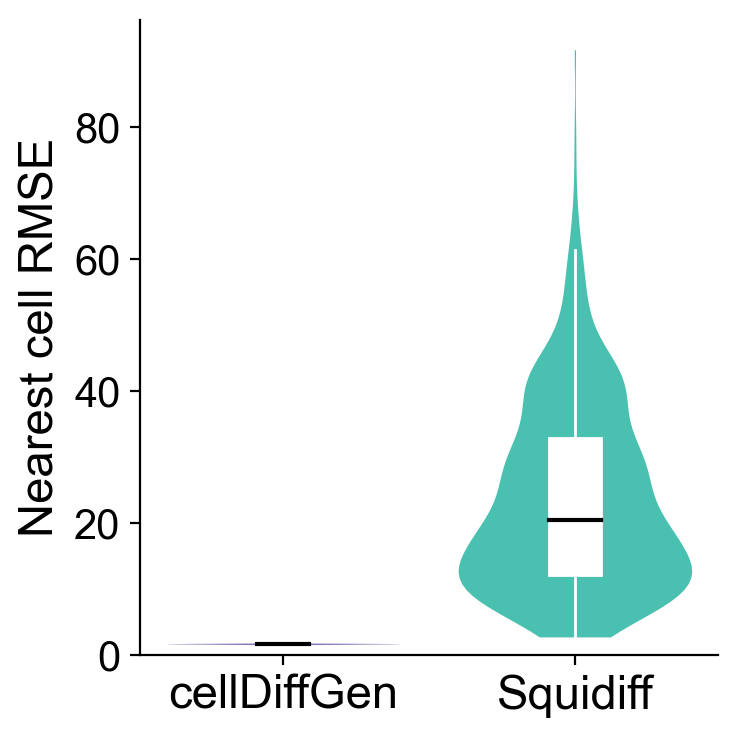

real_data: View of AnnData object with n_obs × n_vars = 600 × 400
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 400
squidiff_data: AnnData object with n_obs × n_vars = 600 × 400
400 400 400
                  mean     median         max
Sample                                       
Squidiff     51.289153  50.746736  106.975381
cellDiffGen   1.740950   1.743779    1.913056


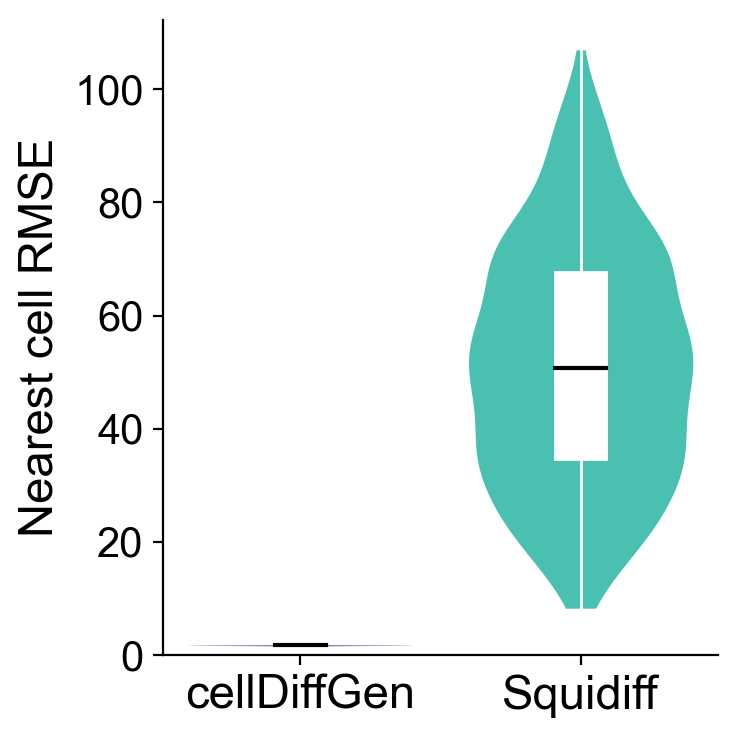

real_data: View of AnnData object with n_obs × n_vars = 600 × 500
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 500
squidiff_data: AnnData object with n_obs × n_vars = 600 × 500
500 500 500
                  mean     median         max
Sample                                       
Squidiff     75.452695  74.905774  132.298296
cellDiffGen   1.787358   1.786537    1.989375


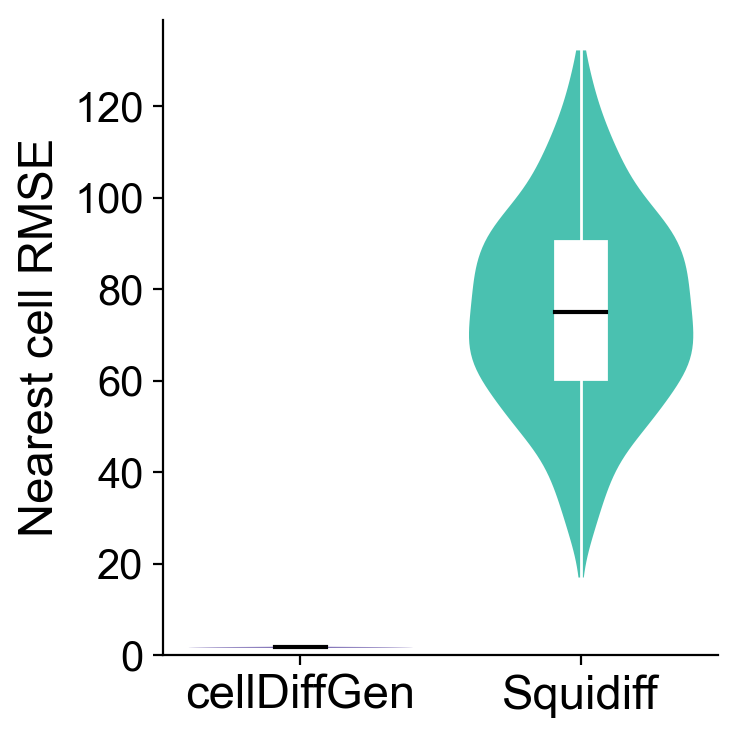

real_data: View of AnnData object with n_obs × n_vars = 600 × 1000
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 1000
squidiff_data: AnnData object with n_obs × n_vars = 600 × 1000
1000 1000 1000
                   mean      median         max
Sample                                         
Squidiff     132.841006  132.322058  195.888739
cellDiffGen    1.855650    1.855141    2.056111


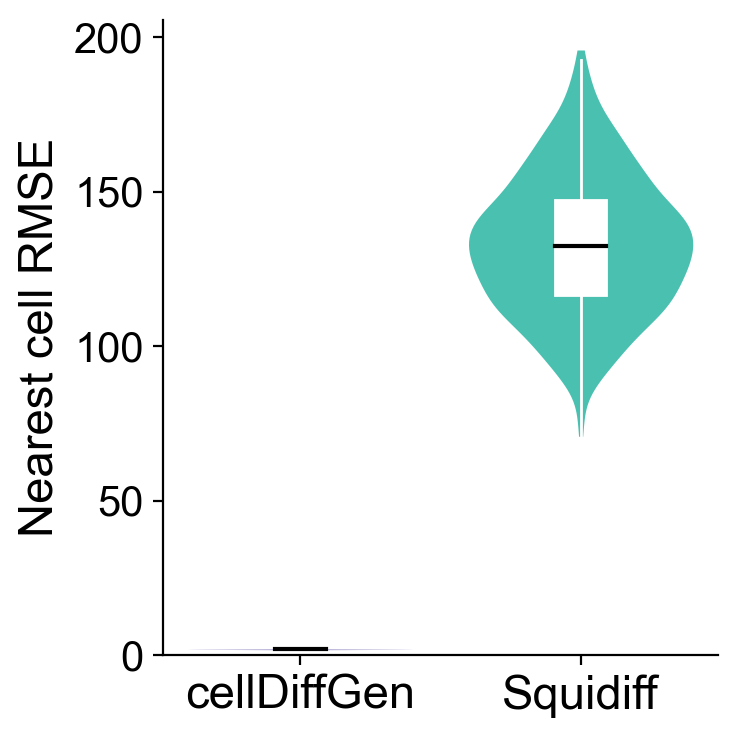

real_data: View of AnnData object with n_obs × n_vars = 600 × 2000
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 2000
squidiff_data: AnnData object with n_obs × n_vars = 600 × 2000
2000 2000 2000
                   mean      median         max
Sample                                         
Squidiff     123.570171  123.942344  157.416108
cellDiffGen    1.524622    1.524726    1.678150


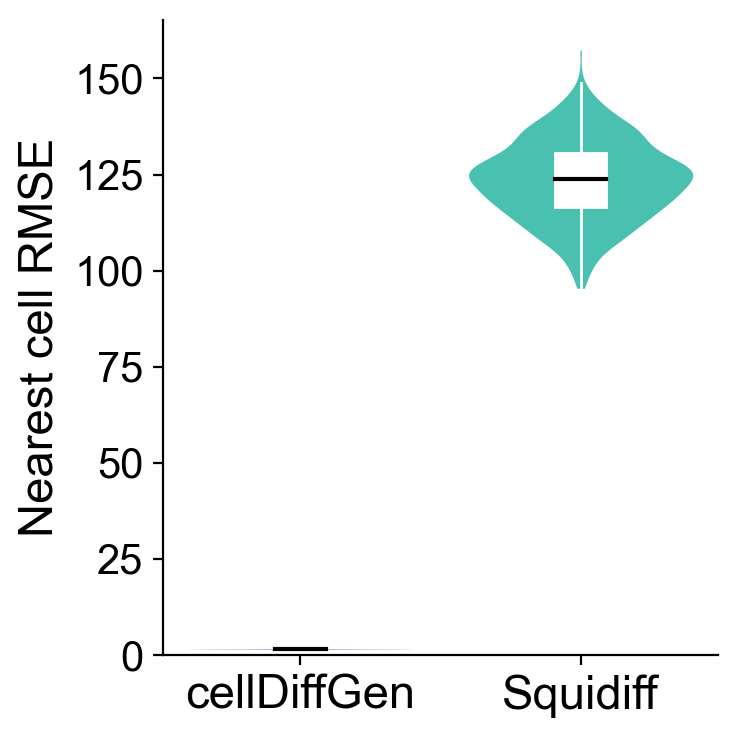

real_data: View of AnnData object with n_obs × n_vars = 600 × 5000
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 5000
squidiff_data: AnnData object with n_obs × n_vars = 600 × 5000
5000 5000 5000
                   mean      median         max
Sample                                         
Squidiff     109.272778  107.325764  140.879694
cellDiffGen    1.833268    1.832066    2.002414


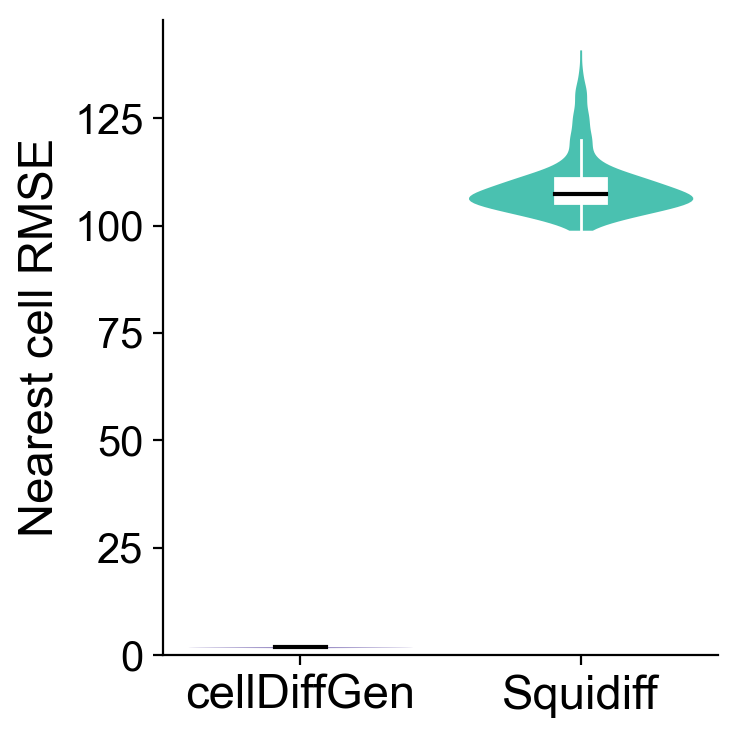

real_data: View of AnnData object with n_obs × n_vars = 600 × 10000
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 10000
squidiff_data: AnnData object with n_obs × n_vars = 600 × 10000
10000 10000 10000
                   mean      median         max
Sample                                         
Squidiff     109.535970  109.522478  112.790781
cellDiffGen    1.760691    1.758480    2.059827


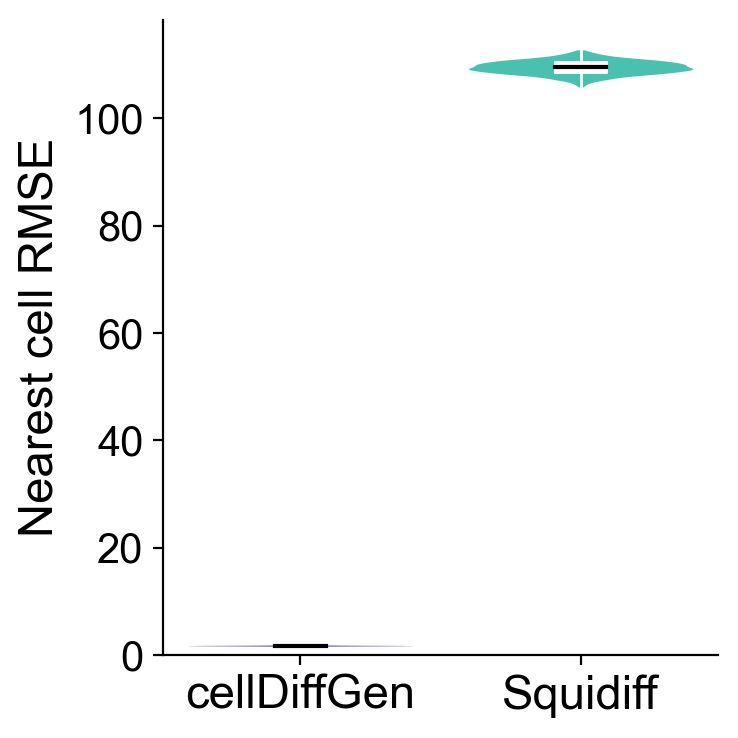

real_data: View of AnnData object with n_obs × n_vars = 600 × 11231
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 11231
squidiff_data: AnnData object with n_obs × n_vars = 600 × 11231
11231 11231 11231
                   mean      median         max
Sample                                         
Squidiff     109.569579  109.508413  114.343157
cellDiffGen    1.835856    1.837574    2.045988


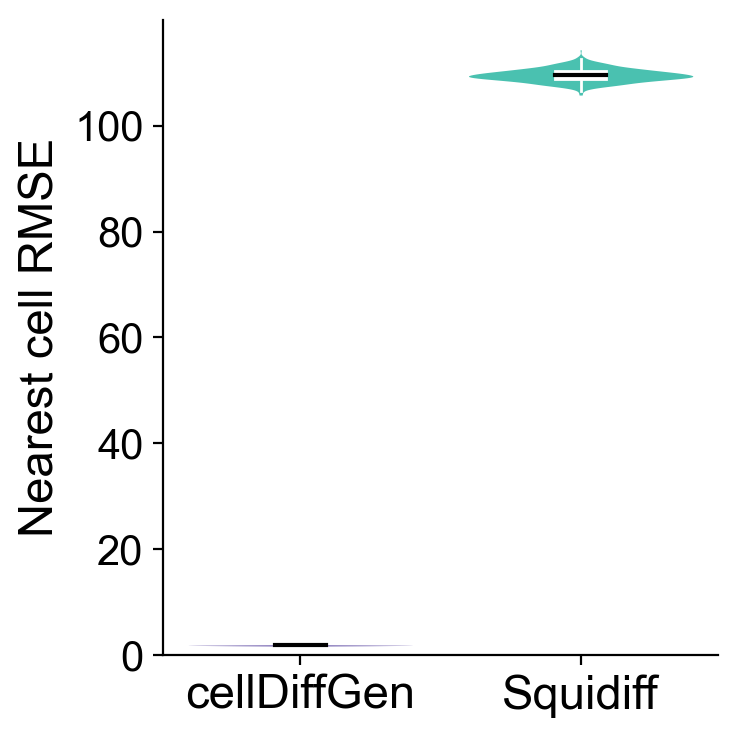

In [7]:
for i in [100,200,203,250,300,400,500,1000,2000,5000,10000,11231]:
    real_data_origin = sc.read_h5ad(f"../../input/diff_test_gene_num_{i}.h5ad")
    real_adata = real_data_origin[real_data_origin.obs['Group']==3]
    # real_data = sc.read_h5ad("../../input/test_day0_data.h5ad")
    print("real_data:",real_adata)

    predict_data = sc.read_h5ad(f"../experiments/exp5_day0_predict_day3_gene_num_{i}/interception_predict_to_day_3.h5ad")
    print("predict_data:",predict_data)
    squidiff_data = sc.read_h5ad(f"../../squidiff/experiments/squidiff_exp5_extend_day0_predict_day3_gene_num_{i}.h5ad")
    print("squidiff_data:",squidiff_data)
    get_pairwise_new(squidiff_data,predict_data, real_adata,i)

In [8]:
# import numpy as np
# from sklearn.decomposition import PCA
# from sklearn.metrics import silhouette_score
# import matplotlib.pyplot as plt
# import ndtest
# from sklearn.preprocessing import MinMaxScaler
# from sklearn.metrics import DistanceMetric

# def get_pairwase_2d(x1, x2, x3, num):
#     x1_np = x1.X if isinstance(x1.X, np.ndarray) else x1.X.toarray()
#     x2_np = x2.X if isinstance(x2.X, np.ndarray) else x2.X.toarray()
#     x3_np = x3.X if isinstance(x3.X, np.ndarray) else x3.X.toarray()
    
#     print("squidiff vs new method vs real data cells number:", len(x1_np), len(x2_np), len(x3_np))

#     X_all = np.vstack([x1_np, x2_np, x3_np])
    
#     # track source
#     index = np.array(['x1'] * len(x1_np) + ['x2'] * len(x2_np) + ['x3'] * len(x3_np))

#     pca = PCA(n_components=2)
#     X_all_2d_before = pca.fit_transform(X_all)

#     scaler = MinMaxScaler()
#     X_all_2d = scaler.fit_transform(X_all_2d_before)   # scaled to [0, 1]

#     # separate by source
#     x1_2d = X_all_2d[index == 'x1']   # squidiff
#     x2_2d = X_all_2d[index == 'x2']   # new_method
#     x3_2d = X_all_2d[index == 'x3']   # real

#     dist = DistanceMetric.get_metric('euclidean')

#     # squidiff vs real
#     D_s = dist.pairwise(x1_2d, x3_2d)
#     all_distances_s = D_s.flatten()

#     # new method vs real
#     D_n = dist.pairwise(x2_2d, x3_2d)
#     all_distances_n = D_n.flatten()
    
#     df = pd.DataFrame({
#         'Sample': ['cellDiffGen'] * len(all_distances_n) + ['Squidiff'] * len(all_distances_s),
#         'distance': list(all_distances_n) + list(all_distances_s)
        
#     })

#     # plt.figure(figsize=(2.5, 4), dpi=200)

#     # Violin plot for KS statistics
#     order = ["cellDiffGen", "Squidiff"]
#     colors = ["#8273B8", "#4AC1B0"]

#     fig, ax = plt.subplots(figsize=(4, 4), dpi=200)

#     sns.violinplot(
#         data=df,
#         x="Sample", y="distance",
#         order=order,
#         hue="Sample", hue_order=order,
#         palette=colors,
#         legend=False,
#         cut=0,
#         linewidth=0,
#         saturation=1,
#         alpha=1,
#         ax=ax,
#         inner='box'
#     )

#     # White box plots inside the violins
#     values = [
#         df.loc[df["Sample"] == name, "distance"]
#         for name in order
#     ]
#     ax.boxplot(
#         values,
#         positions=[0, 1],
#         widths=0.18,
#         patch_artist=True,
#         showfliers=False,
#         showcaps=False,
#         manage_ticks=False,
#         boxprops=dict(facecolor="white", edgecolor="white", zorder=3),
#         medianprops=dict(color="black", linewidth=1.5, zorder=4),
#         whiskerprops=dict(color="white", linewidth=1, zorder=4)
#     )

#     # Compare the two groups of KS statistics
#     annotator = Annotator(
#         ax, [("cellDiffGen", "Squidiff")],
#         data=df,
#         x="Sample", y="distance",
#         order=order
#     )
#     annotator.configure(
#         test="Mann-Whitney",
#         # text_format="simple",
#         show_test_name=True,
#         # test_short_name="Mann–Whitney",
#         loc="outside",
#         verbose=0
#     )
#     annotator.apply_and_annotate()

#     # Legend above the bracket
#     handles = [
#         Patch(facecolor=color, edgecolor="#555555", label=name)
#         for name, color in zip(order, colors)
#     ]
#     # ax.legend(
#     #     handles=handles,
#     #     loc="lower center",
#     #     bbox_to_anchor=(0.5, 1.20),
#     #     ncol=2,
#     #     frameon=False,
#     #     fontsize=9
#     # )
#     print(df.groupby("Sample")["distance"].max())
#     print("Overall maximum:", df["distance"].max())
#     ax.set_xlabel("")
#     ax.set_ylabel("Euclidean distance")
#     ax.spines["top"].set_visible(False)
#     ax.spines["right"].set_visible(False)
#     ax.set_ylim(0, 1.4)
#     ax.set_yticks(np.arange(0, 1.5, 0.1))
#     ax.tick_params(axis="y", labelsize=15)
#     ax.tick_params(direction="out")
#     ax.grid(False)

#     # fig.savefig(f"ks_ks_stats_compare_gene_num_{i}.pdf", bbox_inches="tight")
#     # plt.show()
#     # plt.close(fig)

#     # plt.ylabel('Euclidean distance')
#     # plt.title(f'Euclidean distance comparison gene num {num}')
#     plt.savefig(f"Euclidean_distance_after_PCA_compare_gene_num_{num}_violin.pdf", bbox_inches="tight")
#     plt.show()

In [9]:
# for i in [100,200,203,250,300,400,500,1000,2000,5000,10000,11231]:
#     real_data_origin = sc.read_h5ad(f"../../input/diff_test_gene_num_{i}.h5ad")
#     real_adata = real_data_origin[real_data_origin.obs['Group']==3]
#     # real_data = sc.read_h5ad("../../input/test_day0_data.h5ad")
#     print("real_data:",real_adata)

#     predict_data = sc.read_h5ad(f"../experiments/exp5_day0_predict_day3_gene_num_{i}/interception_predict_to_day_3.h5ad")
#     print("predict_data:",predict_data)
#     squidiff_data = sc.read_h5ad(f"../../squidiff/experiments/squidiff_exp5_extend_day0_predict_day3_gene_num_{i}.h5ad")
#     print("squidiff_data:",squidiff_data)
#     get_pairwase_2d(squidiff_data,predict_data, real_adata,i)

In [10]:

# for i in [100,200,203,250,300,400]:
#     real_data_origin = sc.read_h5ad(f"../../input/diff_test_gene_num_{i}.h5ad")
#     real_adata = real_data_origin[real_data_origin.obs['Group']==3]
#     # real_data = sc.read_h5ad("../../input/test_day0_data.h5ad")
#     print("real_data:",real_adata)

#     predict_data = sc.read_h5ad(f"../experiments/exp5_day0_predict_day3_gene_num_{i}/interception_predict_to_day_3.h5ad")
#     print("predict_data:",predict_data)
#     squidiff_data = sc.read_h5ad(f"../../squidiff/experiments/squidiff_exp5_extend_day0_predict_day3_gene_num_{i}.h5ad")
#     print("squidiff_data:",squidiff_data)
    
#     ks_stats_1, p_values_1 = ks_per_gene(predict_data, real_adata)

#     df_ks_1 = pd.DataFrame({
#         'Sample': [f'our_method'] * len(ks_stats_1),
#         'KS_stat': ks_stats_1,
#         'neglog10_p_value': -np.log10(p_values_1)
#     })

#     # second sample
#     ks_stats_2, p_values_2 = ks_per_gene(squidiff_data, real_adata)

#     df_ks_2 = pd.DataFrame({
#         'Sample': [f'squidiff'] * len(ks_stats_2),
#         'KS_stat': ks_stats_2,
#         'neglog10_p_value': -np.log10(p_values_2)
#     })

#     # combine
#     df_ks_all = pd.concat([df_ks_1, df_ks_2], ignore_index=True)
#     print(len(df_ks_all))
#     # print(df_ks_all.head(5))
#     plt.figure(figsize=(4, 2), dpi=100)
#     sns.boxplot(x='Sample', y='neglog10_p_value', data=df_ks_all, palette=['red', 'blue'])
#     plt.title(f"Per-gene KS statistics: neglog10_p_value, gene num {i}")
#     plt.savefig(f"ks_p_value_compare_gene_num_{i}.pdf", bbox_inches="tight")
#     # plt.show()
#     plt.figure(figsize=(4, 2), dpi=100)
#     sns.boxplot(x='Sample', y='KS_stat', data=df_ks_all, palette=['red', 'blue'])
#     plt.title(f"Per-gene KS statistics: KS_stat, gene num {i}")
#     plt.savefig(f"ks_ks_stats_compare_gene_num_{i}.pdf", bbox_inches="tight")
    # plt.show()

    # print("new method vs squidiff median:", np.median(ks_stats_1), np.median(ks_stats_2))
    # print("new method vs squidiff highest:", np.max(ks_stats_1), np.max(ks_stats_2))
    # print("new method vs squidiff lowest:", np.min(ks_stats_1), np.min(ks_stats_2))
    # print("new method vs squidiff range:", np.max(ks_stats_1) - np.min(ks_stats_1), np.max(ks_stats_2) - np.min(ks_stats_2))

## compare mainly by D, smaller D is better, larger P is better

real_data: View of AnnData object with n_obs × n_vars = 600 × 100
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 100
squidiff_data: AnnData object with n_obs × n_vars = 600 × 100
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 100: P=6.4e-15, D=0.282
new method vs real data, gene num 100: P=2.43e-33, D=0.425
squidiff vs new method, gene num 100: P=5.12e-15, D=0.282
Silhouette squidiff vs real data, gene num 100: 0.0390
Silhouette new method vs real data, gene num 100: 0.0778
Silhouette squidiff vs new method, gene num 100: 0.0468


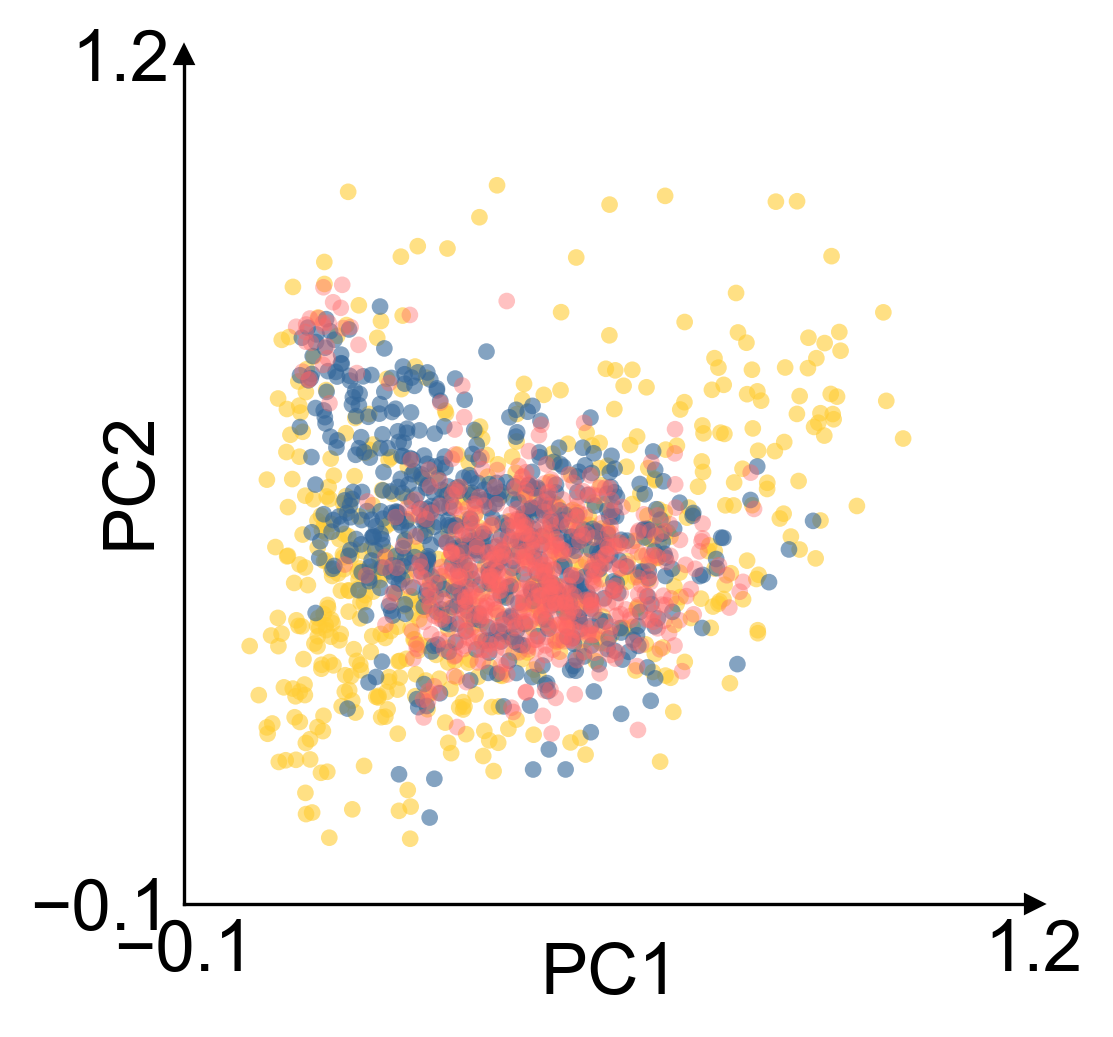

real_data: View of AnnData object with n_obs × n_vars = 600 × 200
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 200
squidiff_data: AnnData object with n_obs × n_vars = 600 × 200
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 200: P=8.7e-14, D=0.268
new method vs real data, gene num 200: P=5.7e-16, D=0.289
squidiff vs new method, gene num 200: P=7.08e-39, D=0.462
Silhouette squidiff vs real data, gene num 200: 0.0435
Silhouette new method vs real data, gene num 200: 0.0325
Silhouette squidiff vs new method, gene num 200: 0.0635


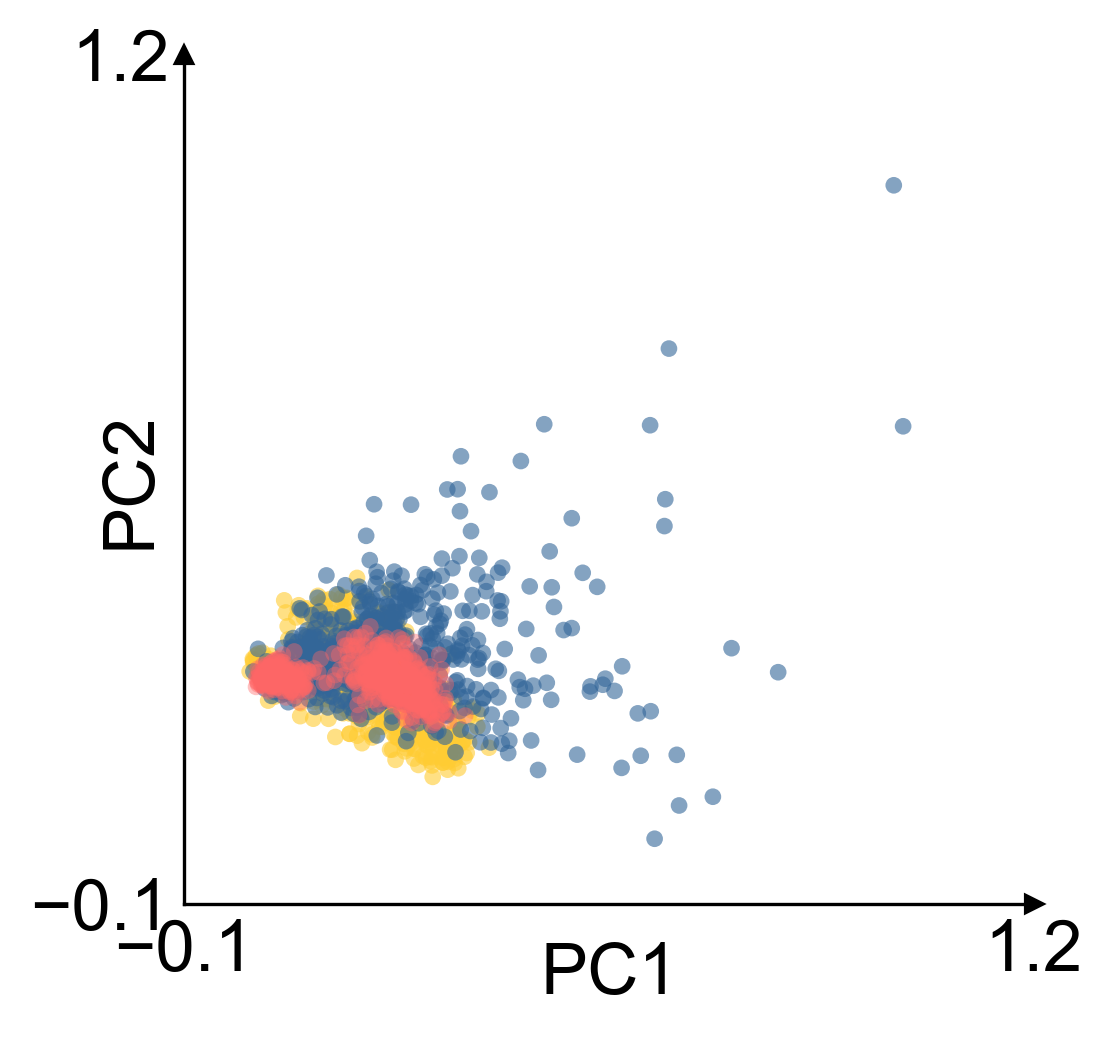

real_data: View of AnnData object with n_obs × n_vars = 600 × 203
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 203
squidiff_data: AnnData object with n_obs × n_vars = 600 × 203
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 203: P=3.34e-27, D=0.379
new method vs real data, gene num 203: P=5.98e-29, D=0.39
squidiff vs new method, gene num 203: P=3.19e-61, D=0.579
Silhouette squidiff vs real data, gene num 203: 0.0841
Silhouette new method vs real data, gene num 203: 0.0627
Silhouette squidiff vs new method, gene num 203: 0.1394


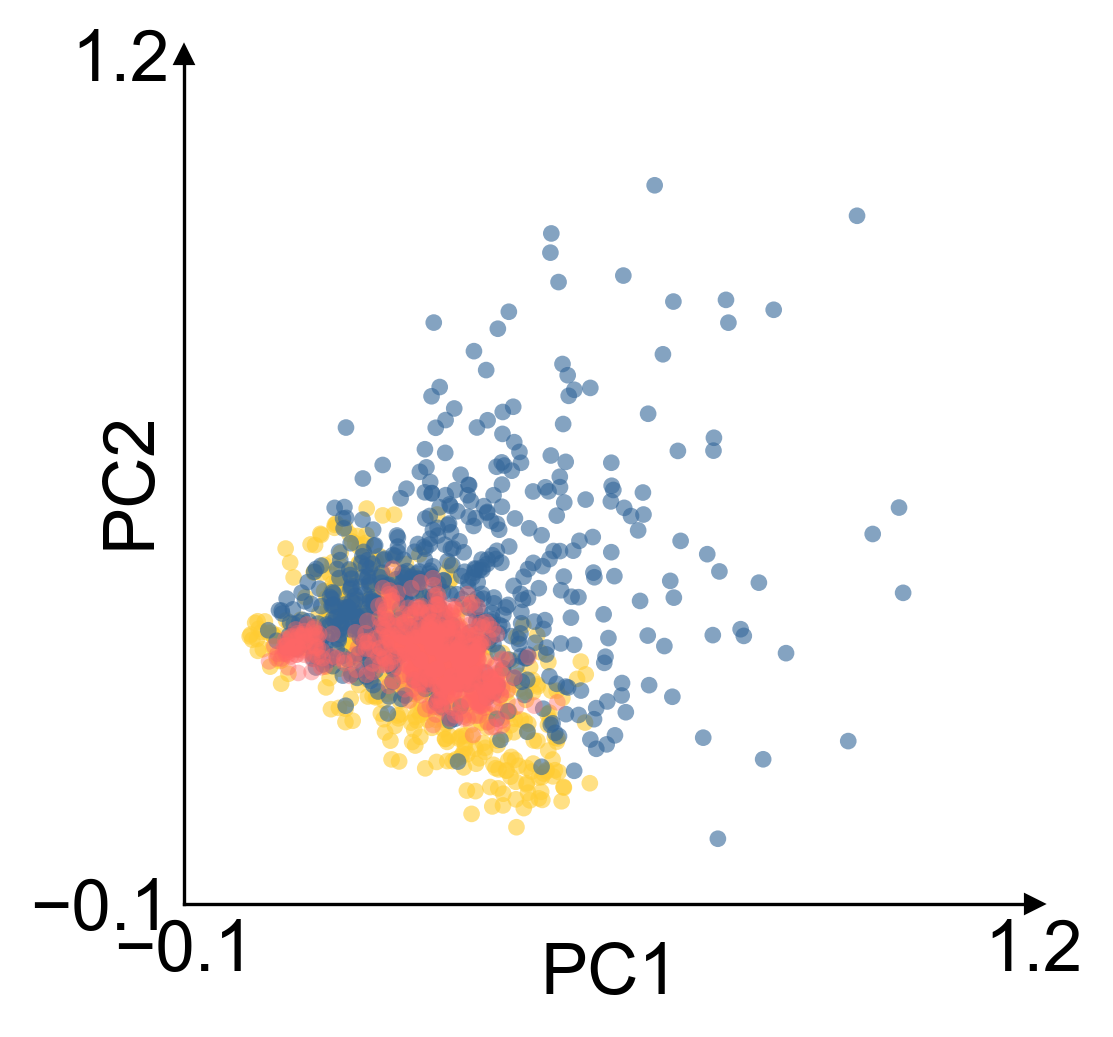

real_data: View of AnnData object with n_obs × n_vars = 600 × 250
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 250
squidiff_data: AnnData object with n_obs × n_vars = 600 × 250
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 250: P=1.78e-153, D=0.907
new method vs real data, gene num 250: P=1.12e-20, D=0.317
squidiff vs new method, gene num 250: P=3.32e-178, D=0.962
Silhouette squidiff vs real data, gene num 250: 0.3959
Silhouette new method vs real data, gene num 250: 0.0426
Silhouette squidiff vs new method, gene num 250: 0.4044


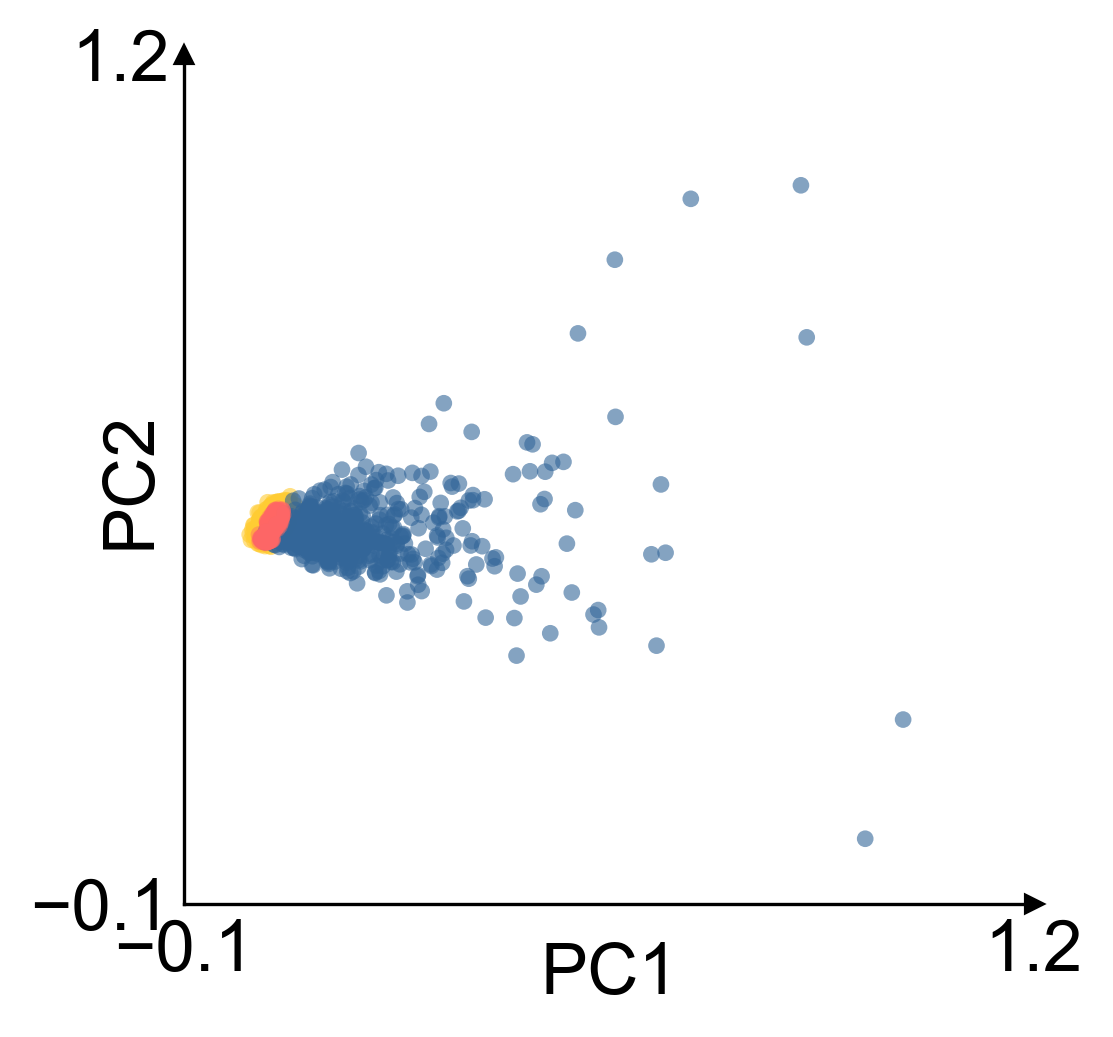

real_data: View of AnnData object with n_obs × n_vars = 600 × 300
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 300
squidiff_data: AnnData object with n_obs × n_vars = 600 × 300
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 300: P=3.78e-176, D=0.987
new method vs real data, gene num 300: P=1.56e-39, D=0.464
squidiff vs new method, gene num 300: P=2.57e-176, D=0.988
Silhouette squidiff vs real data, gene num 300: 0.5251
Silhouette new method vs real data, gene num 300: 0.1217
Silhouette squidiff vs new method, gene num 300: 0.5317


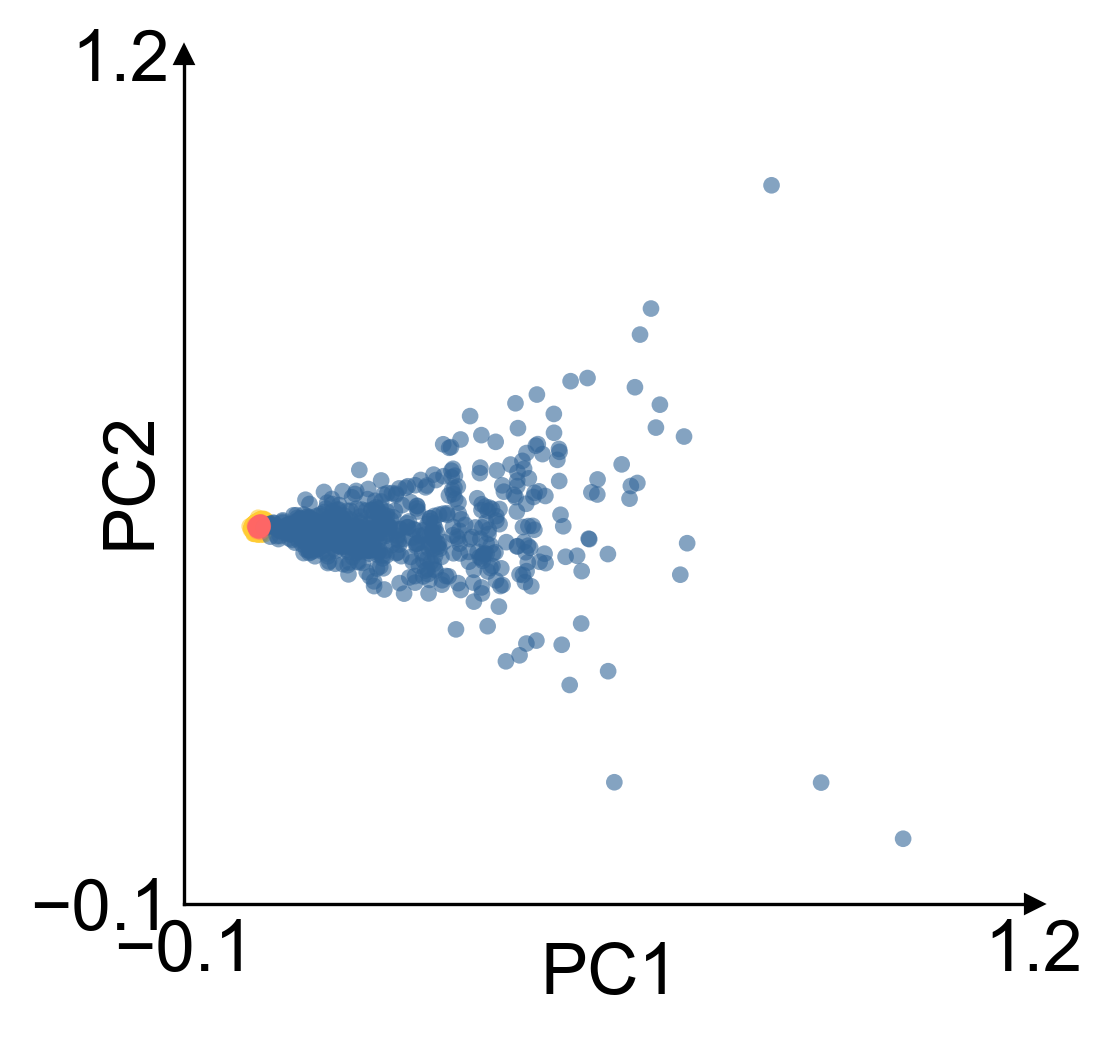

real_data: View of AnnData object with n_obs × n_vars = 600 × 400
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 400
squidiff_data: AnnData object with n_obs × n_vars = 600 × 400
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 400: P=3.13e-165, D=0.958
new method vs real data, gene num 400: P=1.07e-32, D=0.423
squidiff vs new method, gene num 400: P=4.72e-178, D=0.993
Silhouette squidiff vs real data, gene num 400: 0.6390
Silhouette new method vs real data, gene num 400: 0.1006
Silhouette squidiff vs new method, gene num 400: 0.6409


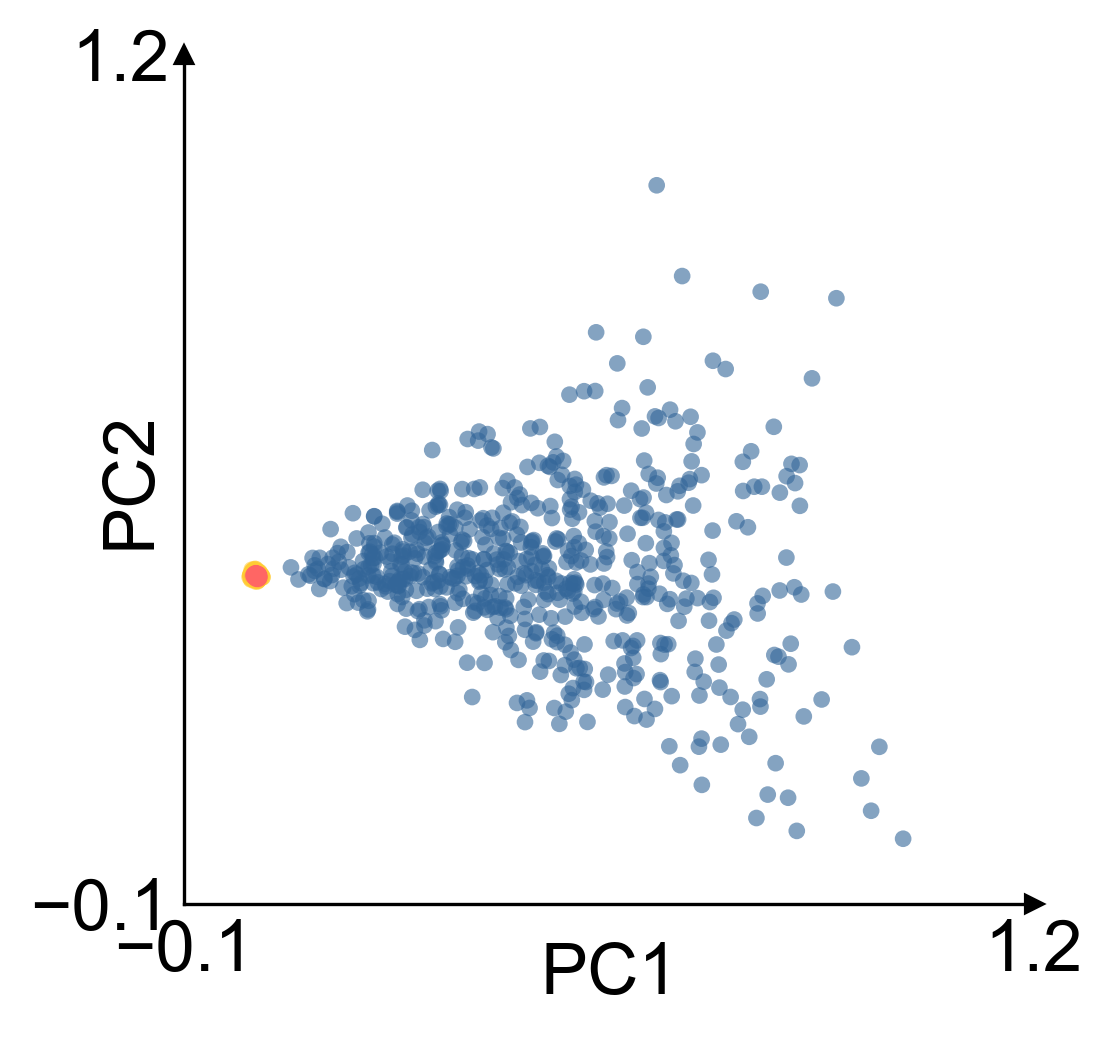

real_data: View of AnnData object with n_obs × n_vars = 600 × 500
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 500
squidiff_data: AnnData object with n_obs × n_vars = 600 × 500
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 500: P=1.87e-178, D=0.987
new method vs real data, gene num 500: P=8.32e-12, D=0.245
squidiff vs new method, gene num 500: P=4.7e-183, D=0.992
Silhouette squidiff vs real data, gene num 500: 0.7335
Silhouette new method vs real data, gene num 500: 0.0311
Silhouette squidiff vs new method, gene num 500: 0.7349


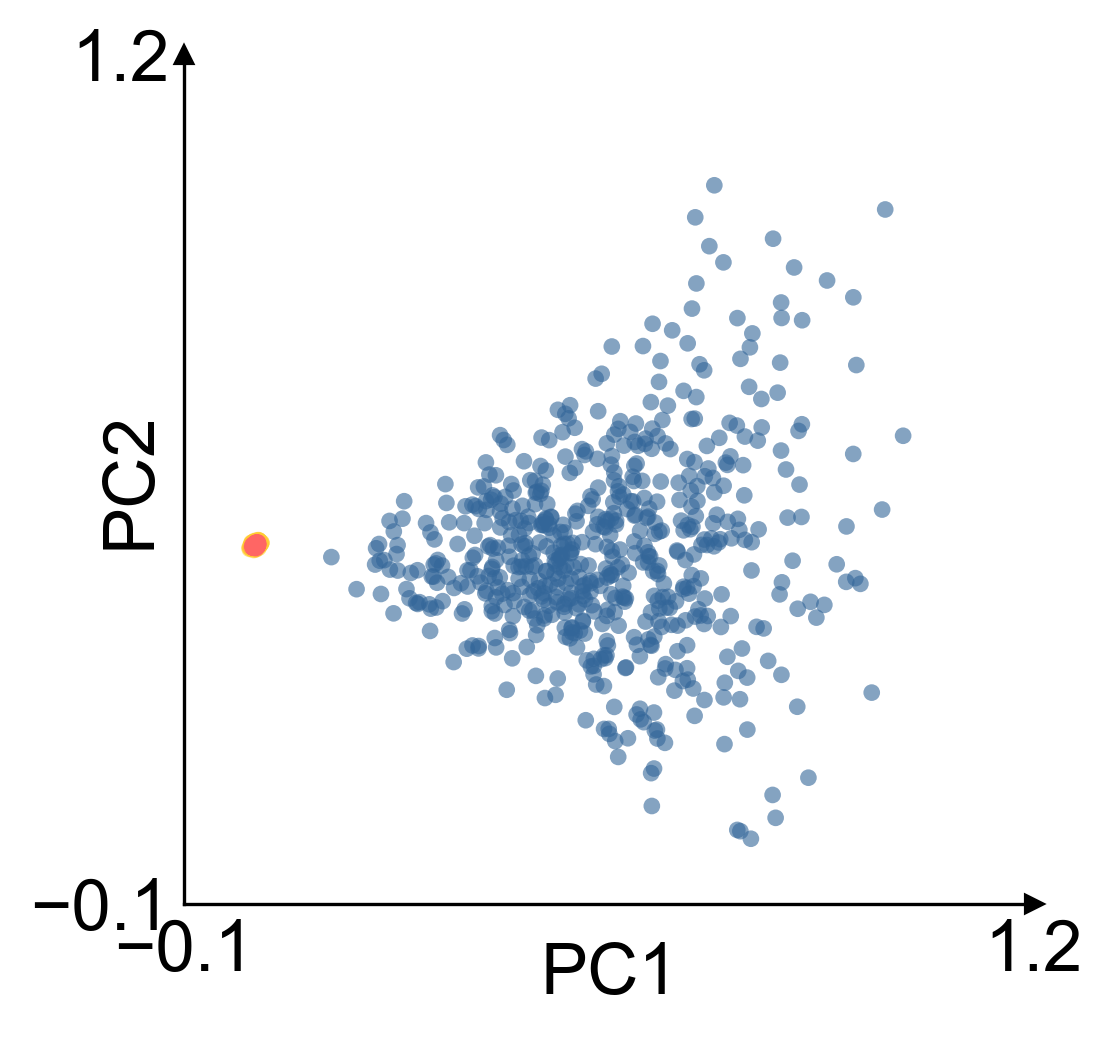

real_data: View of AnnData object with n_obs × n_vars = 600 × 1000
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 1000
squidiff_data: AnnData object with n_obs × n_vars = 600 × 1000
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 1000: P=2.68e-172, D=0.98
new method vs real data, gene num 1000: P=2.58e-45, D=0.501
squidiff vs new method, gene num 1000: P=6.05e-175, D=0.988
Silhouette squidiff vs real data, gene num 1000: 0.8495
Silhouette new method vs real data, gene num 1000: 0.1852
Silhouette squidiff vs new method, gene num 1000: 0.8499


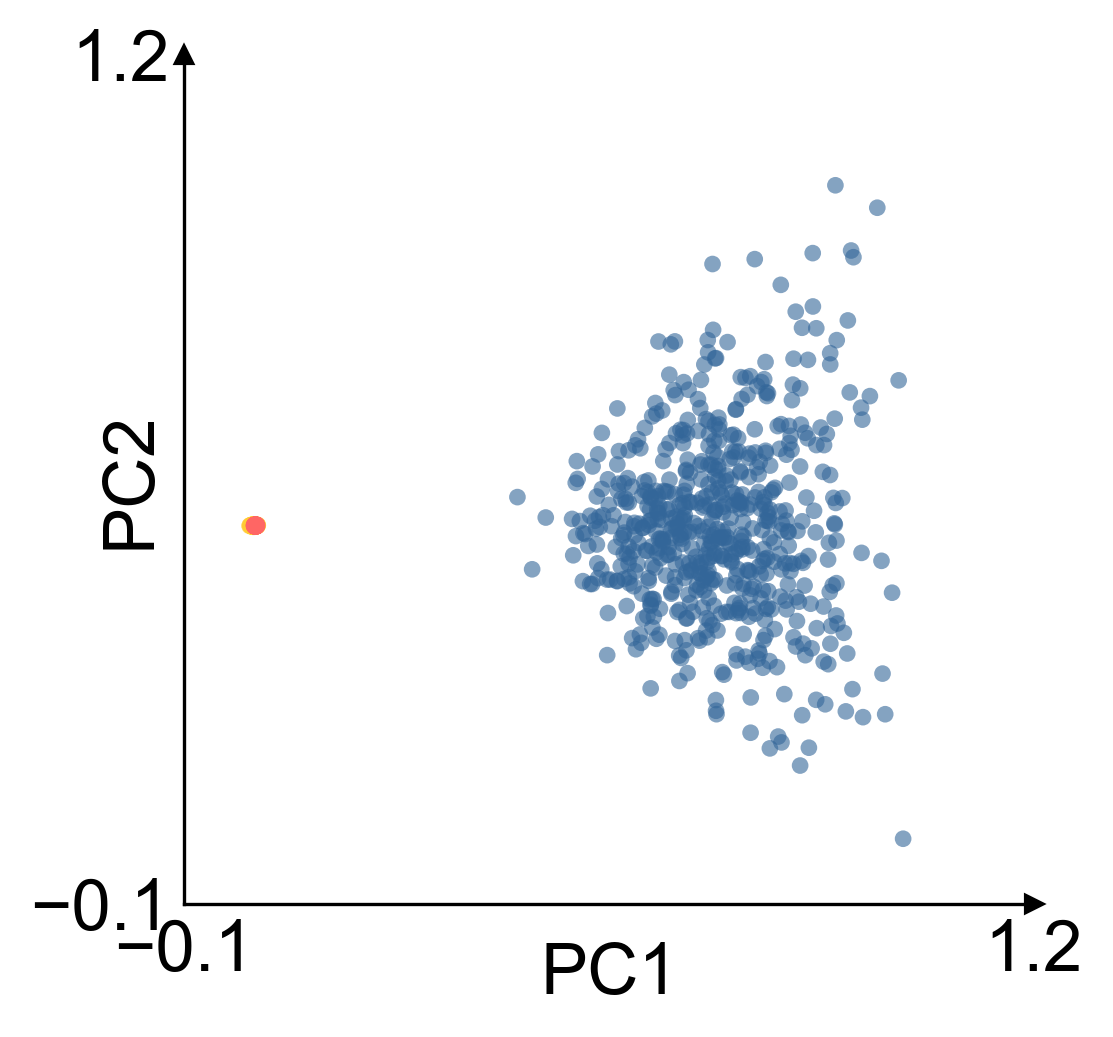

real_data: View of AnnData object with n_obs × n_vars = 600 × 2000
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 2000
squidiff_data: AnnData object with n_obs × n_vars = 600 × 2000
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 2000: P=6.28e-169, D=0.969
new method vs real data, gene num 2000: P=3.14e-29, D=0.396
squidiff vs new method, gene num 2000: P=2.77e-183, D=0.997
Silhouette squidiff vs real data, gene num 2000: 0.8785
Silhouette new method vs real data, gene num 2000: 0.0581
Silhouette squidiff vs new method, gene num 2000: 0.8792


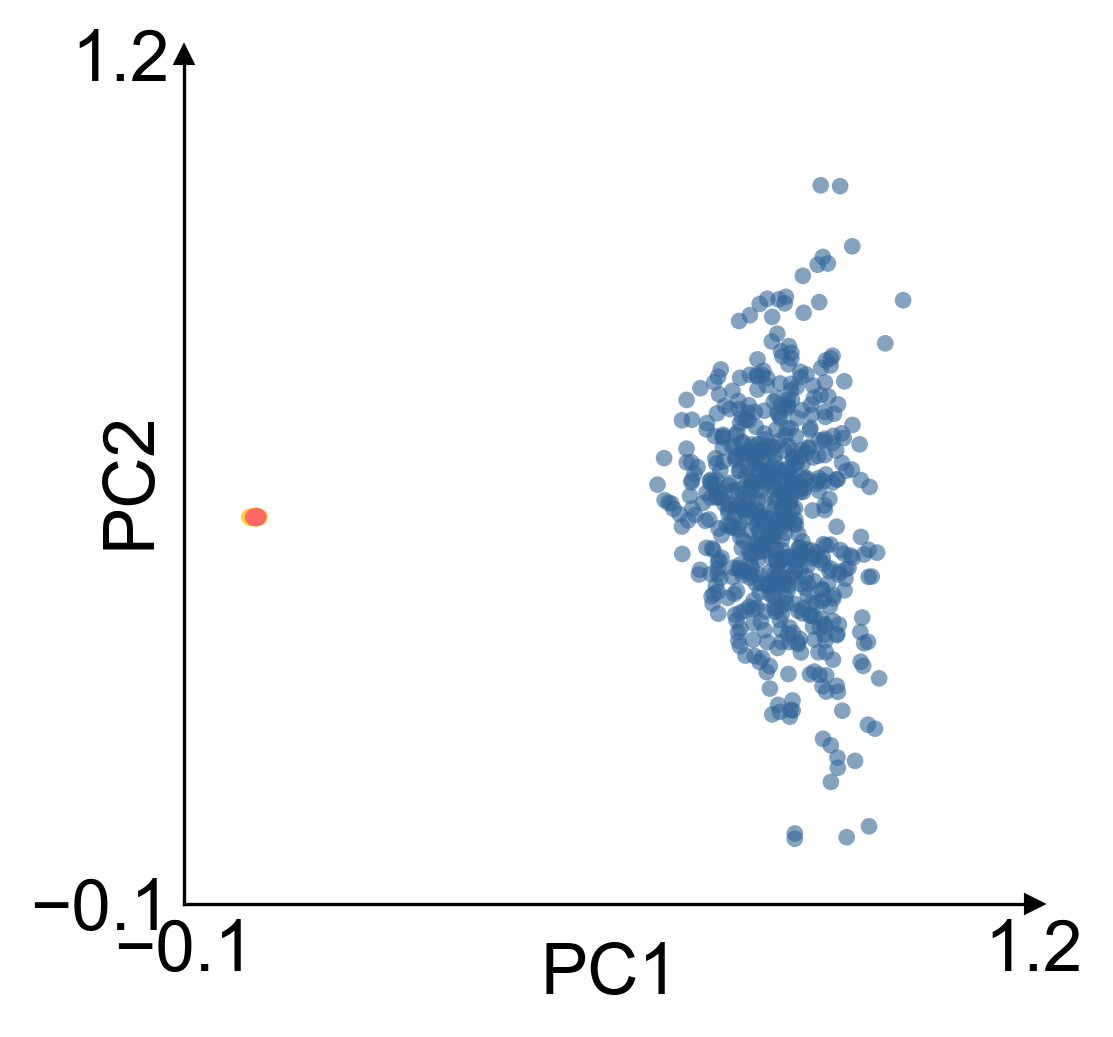

real_data: View of AnnData object with n_obs × n_vars = 600 × 5000
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 5000
squidiff_data: AnnData object with n_obs × n_vars = 600 × 5000
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 5000: P=2.45e-195, D=0.995
new method vs real data, gene num 5000: P=4.94e-38, D=0.448
squidiff vs new method, gene num 5000: P=7.53e-190, D=0.987
Silhouette squidiff vs real data, gene num 5000: 0.8983
Silhouette new method vs real data, gene num 5000: 0.1580
Silhouette squidiff vs new method, gene num 5000: 0.8991


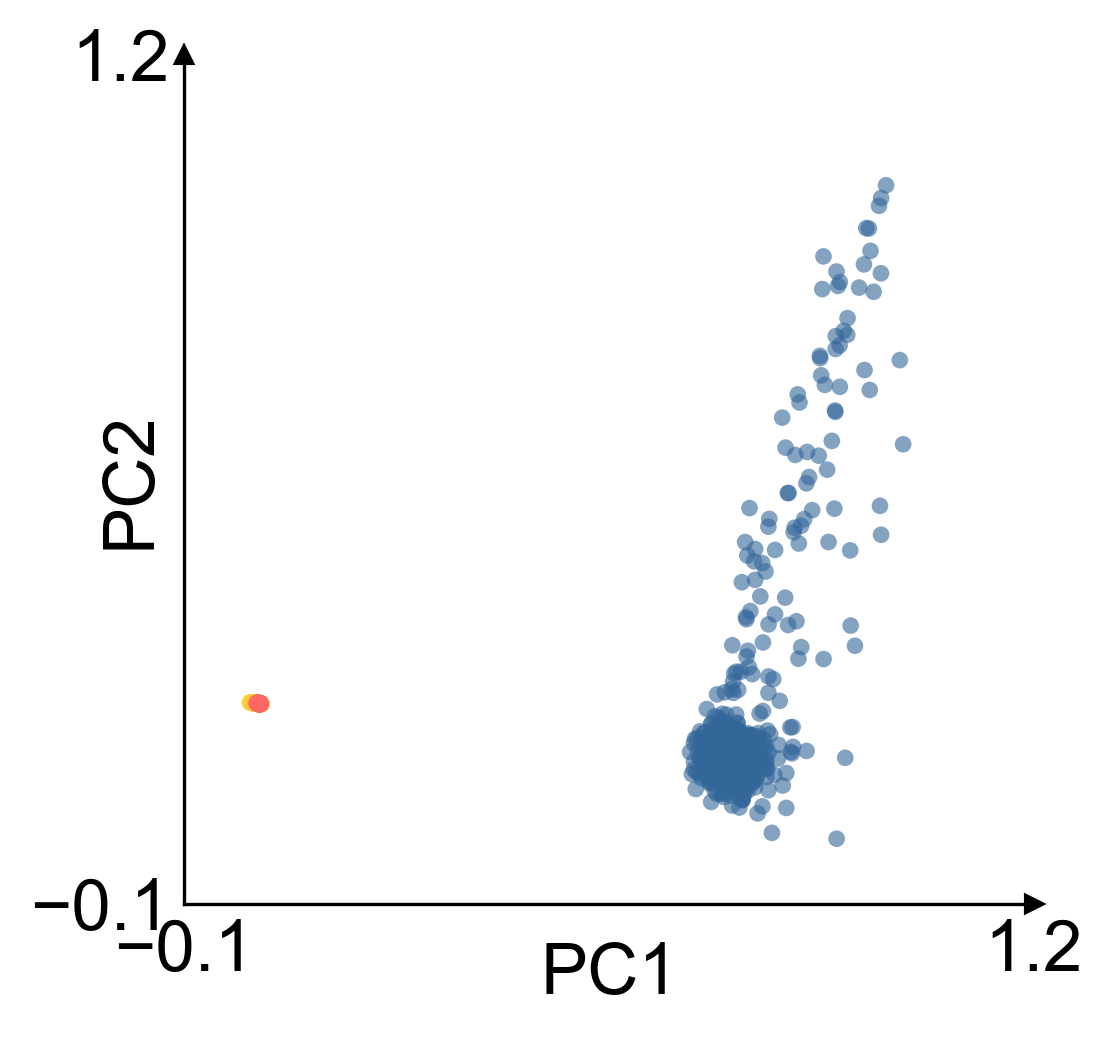

real_data: View of AnnData object with n_obs × n_vars = 600 × 10000
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 10000
squidiff_data: AnnData object with n_obs × n_vars = 600 × 10000
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 10000: P=4.08e-169, D=0.97
new method vs real data, gene num 10000: P=5.29e-41, D=0.476
squidiff vs new method, gene num 10000: P=2.64e-175, D=0.988
Silhouette squidiff vs real data, gene num 10000: 0.8965
Silhouette new method vs real data, gene num 10000: 0.1721
Silhouette squidiff vs new method, gene num 10000: 0.8973


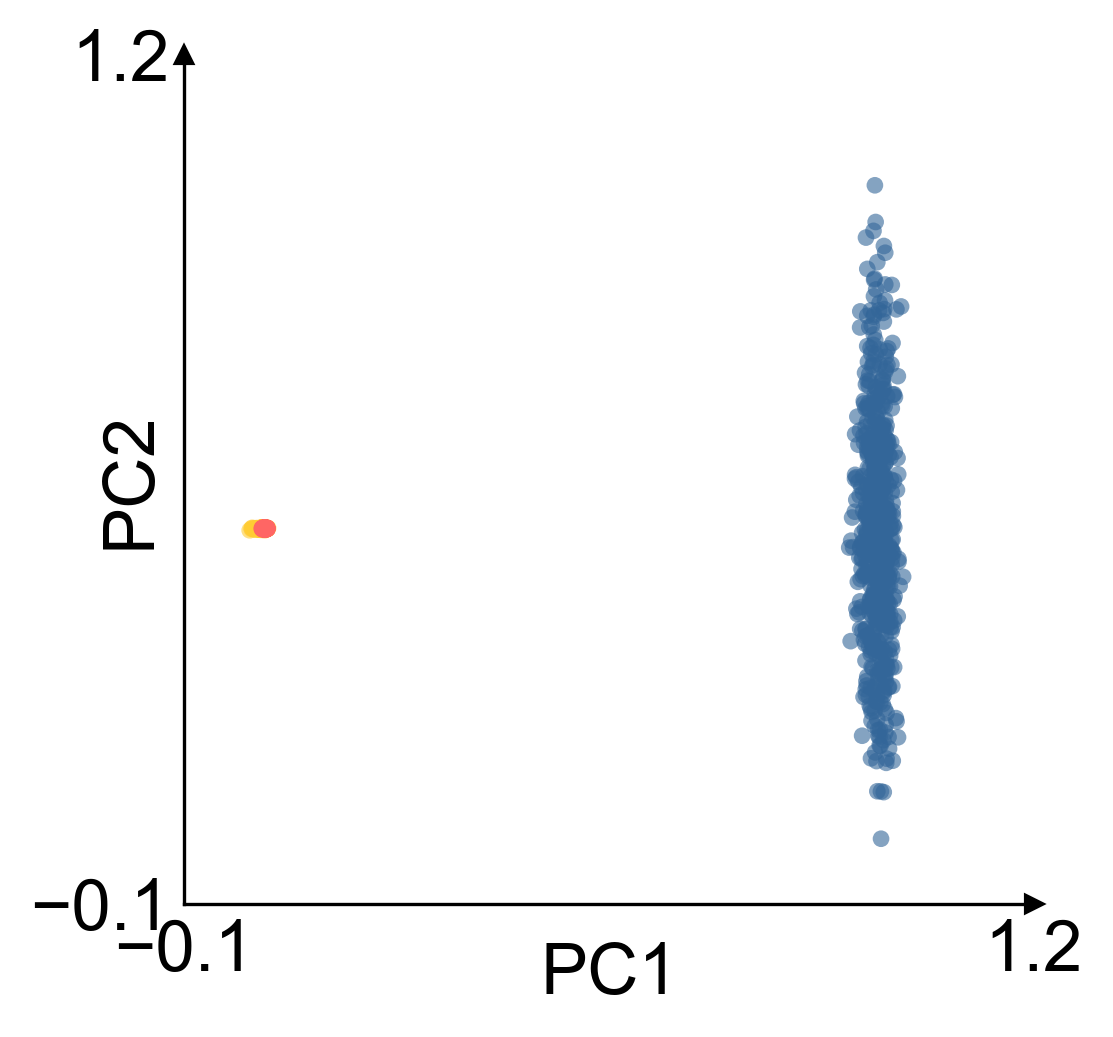

real_data: View of AnnData object with n_obs × n_vars = 600 × 11231
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 11231
squidiff_data: AnnData object with n_obs × n_vars = 600 × 11231
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 11231: P=3.2e-175, D=0.988
new method vs real data, gene num 11231: P=6.22e-13, D=0.264
squidiff vs new method, gene num 11231: P=3.84e-171, D=0.977
Silhouette squidiff vs real data, gene num 11231: 0.9047
Silhouette new method vs real data, gene num 11231: 0.0607
Silhouette squidiff vs new method, gene num 11231: 0.9056


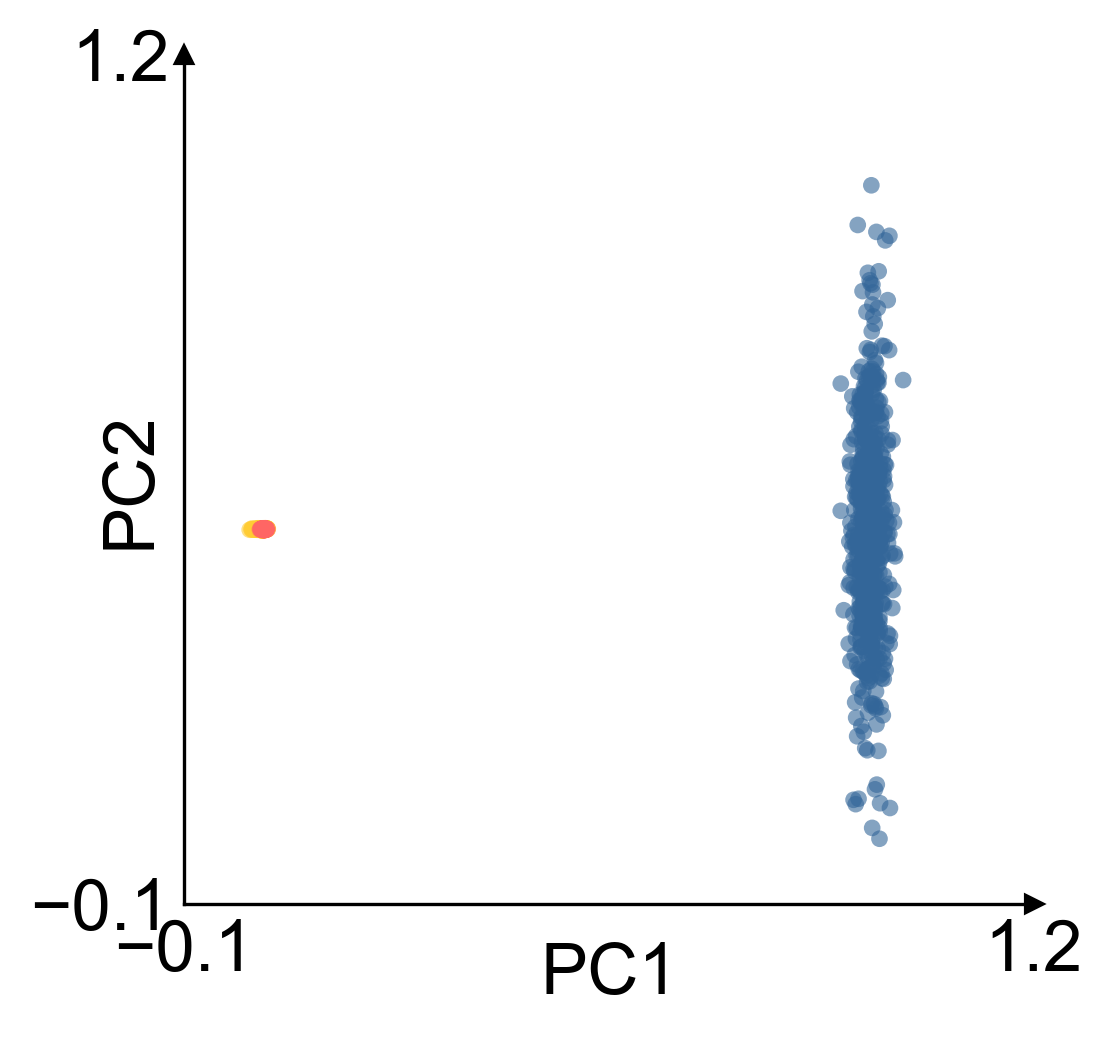

In [11]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import ndtest
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import DistanceMetric

def get_pca_2d(x1, x2, x3, num):
    # x1_np = x1.detach().cpu().numpy()
    # x2_np = x2.detach().cpu().numpy()
    x1_np = x1.X if isinstance(x1.X, np.ndarray) else x1.X.toarray()
    x2_np = x2.X if isinstance(x2.X, np.ndarray) else x2.X.toarray()
    x3_np = x3.X if isinstance(x3.X, np.ndarray) else x3.X.toarray()
    
    print(" squidiff vs new method vs real data cells number:", len(x1_np), len(x2_np), len(x3_np))

    X_all = np.vstack([x1_np, x2_np, x3_np])
    
    # Create index array to track source
    index = np.array(['x1'] * len(x1_np) + ['x2'] * len(x2_np) + ['x3'] * len(x3_np))

    pca = PCA(n_components=2)
    X_all_2d_before = pca.fit_transform(X_all)

    scaler = MinMaxScaler()
    X_all_2d = scaler.fit_transform(X_all_2d_before)   # scaled to [0, 1]
    # Separate by index after PCA
    x1_2d = X_all_2d[index == 'x1']#squidiff
    x2_2d = X_all_2d[index == 'x2']
    x3_2d = X_all_2d[index == 'x3']

    # x1_2d: generated cells, shape (n1, 2)
    # x2_2d: real cells, shape (n2, 2)
    x1 = x1_2d[:, 0]  # PC1 of squidiff
    y1 = x1_2d[:, 1]  # PC2 of squidiff

    x2 = x2_2d[:, 0]  # PC1 of new_method
    y2 = x2_2d[:, 1]  # PC2 of new_method

    x3 = x3_2d[:, 0]  # PC1 of real
    y3 = x3_2d[:, 1]  # PC1 of real
    # print("len",len(x1),len(y1),len(x2),len(y2),len(x3),len(y3))
    P, D = ndtest.ks2d2s(x1, y1, x3, y3, extra=True)
    print(f"squidiff method vs real data, gene num {num}: P={P:.3g}, D={D:.3g}")

    P, D = ndtest.ks2d2s(x2, y2, x3, y3, extra=True)
    print(f"new method vs real data, gene num {num}: P={P:.3g}, D={D:.3g}")

    P, D = ndtest.ks2d2s(x1, y1, x2, y2, extra=True)
    print(f"squidiff vs new method, gene num {num}: P={P:.3g}, D={D:.3g}")


    # silhouette: 0 vs 2
    X_s = np.vstack([x1_2d, x3_2d])
    labels_s = np.array([0] * len(x1_2d) + [1] * len(x3_2d))
    sil_s = silhouette_score(X_s, labels_s)
    print(f"Silhouette squidiff vs real data, gene num {num}: {sil_s:.4f}")

    # silhouette: 1 vs 2
    X_n = np.vstack([x2_2d, x3_2d])
    labels_n = np.array([0] * len(x2_2d) + [1] * len(x3_2d))
    sil_n = silhouette_score(X_n, labels_n)
    print(f"Silhouette new method vs real data, gene num {num}: {sil_n:.4f}")

    X_n = np.vstack([x1_2d, x2_2d])
    labels_n = np.array([0] * len(x1_2d) + [1] * len(x2_2d))
    sil_n = silhouette_score(X_n, labels_n)
    print(f"Silhouette squidiff vs new method, gene num {num}: {sil_n:.4f}")

#     fig,ax = plt.figure(figsize=(2, 2), dpi=300)
    fig, ax = plt.subplots(figsize=(4, 4), dpi=300)
    ax.scatter(x3, y3, s=16, alpha=0.6, c='#FFCC33', label='real data',edgecolors='none')
    ax.scatter(x1, y1, s=16, alpha=0.6, c='#336699', label='Squidiff',edgecolors='none')
    ax.scatter(x2, y2, s=16, alpha=0.4, c='#FF6666', label='cellDiffGen',edgecolors='none')
    


    ax.set_xlim(-0.1, 1.2)
    ax.set_ylim(-0.1, 1.2)
    # Only show endpoint numbers
    ax.set_xticks([-0.1, 1.2])
    ax.set_yticks([-0.1, 1.2])
    # ax.set_yticklabels(["-0.1", "2"])
    # Keep bottom and left borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)

    # ax.tick_params(top=False, right=False)
    # ax.grid(False)
    ax.tick_params(axis="both", which="both", length=0)
    # Arrowheads at the ends of the axes
    ax.plot(1, -0.1, marker=">", color="black", markersize=4,
            transform=ax.get_yaxis_transform(), clip_on=False)
    ax.plot(-0.1, 1, marker="^", color="black", markersize=4,
            transform=ax.get_xaxis_transform(), clip_on=False)
    plt.xlabel("PC1", labelpad=-10)
    plt.ylabel("PC2", labelpad=-32)
    ax.set_aspect("equal", adjustable="box")
    # plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.savefig(f"ks_pca_compare_gene_num_{num}.pdf", bbox_inches="tight")
    plt.show()

for i in [100,200,203,250,300,400,500,1000,2000,5000,10000,11231]:
# for i in [250]:
    real_data_origin = sc.read_h5ad(f"../../input/diff_test_gene_num_{i}.h5ad")
    real_adata = real_data_origin[real_data_origin.obs['Group']==3]
    # real_data = sc.read_h5ad("../../input/test_day0_data.h5ad")
    print("real_data:",real_adata)

    predict_data = sc.read_h5ad(f"../experiments/exp5_day0_predict_day3_gene_num_{i}/interception_predict_to_day_3.h5ad")
    print("predict_data:",predict_data)
    squidiff_data = sc.read_h5ad(f"../../squidiff/experiments/squidiff_exp5_extend_day0_predict_day3_gene_num_{i}.h5ad")
    print("squidiff_data:",squidiff_data)
    # get_pairwase_2d(squidiff_data,predict_data, real_adata,i)
    get_pca_2d(squidiff_data, predict_data, real_adata,i)